In [1]:
import os, glob, json, hashlib, time, shutil, warnings
from copy import deepcopy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.signal import welch, butter, freqz
from scipy.ndimage import uniform_filter1d

import bci_pipeline as bp

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)

cfg = bp.load_config()                      # the ONE shared config
FS, CH, SEED = cfg["fs"], cfg["channels"], cfg["random_seed"]
C3, C4 = CH.index("C3"), CH.index("C4")
OUT, MODELS_DIR = "outputs", "models"
os.makedirs(OUT, exist_ok=True); os.makedirs(MODELS_DIR, exist_ok=True)
np.random.seed(SEED)

plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
COL = {"LEFT": "#1f77b4", "RIGHT": "#ff7f0e"}

print(json.dumps({k: v for k, v in cfg.items() if k != "data"}, indent=1))

{
 "project": "BCI Motor Imagery Classification (LEFT vs RIGHT)",
 "pipeline_version": "1.0.0",
 "fs": 250,
 "trial_seconds": 10,
 "channels": [
  "FZ",
  "C3",
  "CZ",
  "C4"
 ],
 "class_names": [
  "LEFT",
  "RIGHT"
 ],
 "bandpass_hz": [
  0.5,
  40
 ],
 "notch_hz": 50,
 "notch_q": 30,
 "artifact": {
  "edge_seconds": 1.0,
  "iqr_factor": 3,
  "flat_share_limit": 0.1
 },
 "use_car": false,
 "epoch_seconds": [
  1.0,
  9.0
 ],
 "csp_band_hz": [
  8,
  30
 ],
 "csp_components": 4,
 "dl_downsample": 2,
 "dl": {
  "max_epochs": 40,
  "batch_size": 32,
  "learning_rate": 0.001,
  "patience": 8,
  "val_share": 0.15
 },
 "session_gap_seconds": 60,
 "cv_folds": 5,
 "random_seed": 42
}


# Stage 1 — Data
## Step 1: Load & Organize
**Task says:** *"Read all ~2000 Excel files, attach LEFT/RIGHT labels, verify sampling rate and channel names."* and *"Keep a clean mapping (filename → label)."*

### 1.1 Find the trial files and attach the labels
- **Did:** Found every trial file, sorted them by their **number** (a text sort would put `10` before `2` and mix up the labels), read `labels.csv`, cleaned the labels (`Left` → `LEFT`), and saved the `filename → label` map.
- **Why:** Every later step depends on each trial carrying the right label.

In [2]:
files = glob.glob(cfg["data"]["trial_glob"], recursive=True)
num = lambda p: int(os.path.basename(p).replace("cellula_MI_data_", "").replace(".csv", ""))
files = sorted(files, key=num)
labels_raw = pd.read_csv(cfg["data"]["labels_csv"])

print("Trial files found:     ", len(files), "| format:", sorted({os.path.splitext(f)[1] for f in files}))
print("Rows in labels.csv:    ", len(labels_raw), "| columns:", list(labels_raw.columns))
print("File numbers are 1..N with no gaps:", [num(f) for f in files] == list(range(1, len(files) + 1)))

labels = labels_raw["label"].astype(str).str.strip().str.upper()
label_map = pd.DataFrame({"filename": [os.path.basename(f) for f in files],
                          "path": files,
                          "label": labels.iloc[:len(files)].values})
print("Label values:", sorted(label_map["label"].unique()))
print("Labels with no file (not used):", len(labels_raw) - len(files))
print("Class counts:", label_map["label"].value_counts().to_dict())

label_map[["filename", "label"]].to_csv(f"{OUT}/label_map.csv", index=False)
print(f"Saved {OUT}/label_map.csv")
label_map.head()

Trial files found:      2160 | format: ['.csv']
Rows in labels.csv:     2400 | columns: ['label']
File numbers are 1..N with no gaps: True
Label values: ['LEFT', 'RIGHT']
Labels with no file (not used): 240
Class counts: {'LEFT': 1082, 'RIGHT': 1078}
Saved outputs/label_map.csv


,filename,path,label
0,cellula_MI_data_1.csv,..\MI-20261105T190501Z-1-001\MI\MI CSV\cellula...,LEFT
1,cellula_MI_data_2.csv,..\MI-20261105T190501Z-1-001\MI\MI CSV\cellula...,RIGHT
2,cellula_MI_data_3.csv,..\MI-20261105T190501Z-1-001\MI\MI CSV\cellula...,LEFT
3,cellula_MI_data_4.csv,..\MI-20261105T190501Z-1-001\MI\MI CSV\cellula...,LEFT
4,cellula_MI_data_5.csv,..\MI-20261105T190501Z-1-001\MI\MI CSV\cellula...,LEFT


### 1.2 Read every trial and verify channels, length and sampling rate
- **Did:** Read all trial files once. For each file we kept: channel names, number of rows, NaNs, first/last timestamp, and a fingerprint (hash) of the signal (used later in EDA 3.4 to find copied files).
- **Why:** The task asks to *verify sampling rate and channel names*. All trials must have the same channels and length to be stacked into one array.

Read 2160 files in 24 s
Channel sets:   {'FZ,C3,CZ,C4': 2160}
Rows per file:  {2500: 2160}
Files with NaN: 0
Duration (s):   {'min': 8.734, '50%': 9.985, 'max': 11.48}
Rate = samples / duration (Hz): {'min': 217.69, '50%': 250.27, 'max': 286.13}

File 1: rate from MEDIAN time step = 416 Hz | from MEAN time step = 250.0 Hz

X_raw: (2160, 4, 2500) (trials, channels, samples)


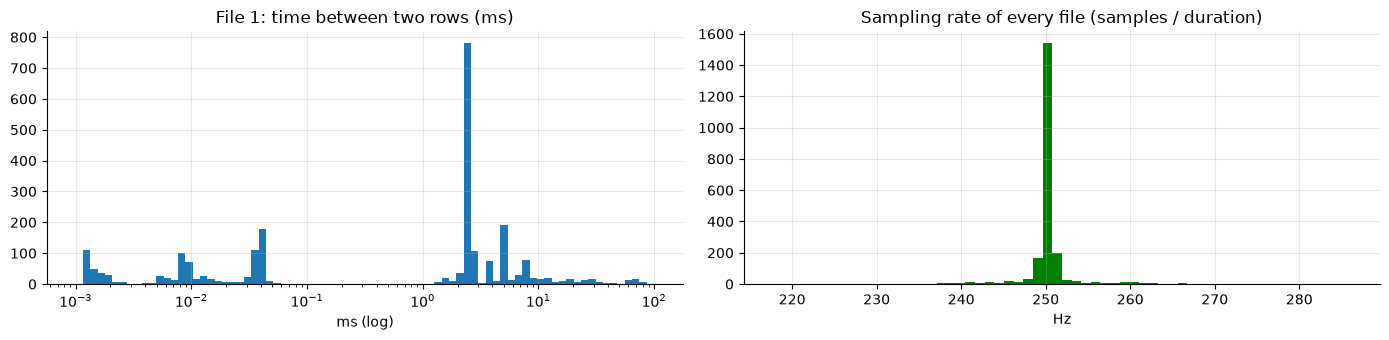

In [3]:
rows, arrays = [], []
t0 = time.time()
for p in label_map["path"]:
    df = pd.read_csv(p)
    sig = df[CH].to_numpy(dtype=float)
    rows.append({"channels": ",".join(c for c in df.columns if c != "Time"),
                 "rows": len(df),
                 "has_nan": bool(df.isna().any().any()),
                 "t_start": df["Time"].iloc[0], "t_end": df["Time"].iloc[-1],
                 "hash": hashlib.md5(np.ascontiguousarray(sig).tobytes()).hexdigest()})
    arrays.append(sig)
trials = pd.concat([label_map, pd.DataFrame(rows)], axis=1)
print(f"Read {len(trials)} files in {time.time() - t0:.0f} s")

trials["duration_s"] = trials["t_end"] - trials["t_start"]
trials["rate_hz"] = (trials["rows"] - 1) / trials["duration_s"]
print("Channel sets:  ", trials["channels"].value_counts().to_dict())
print("Rows per file: ", trials["rows"].value_counts().to_dict())
print("Files with NaN:", int(trials["has_nan"].sum()))
print("Duration (s):  ", trials["duration_s"].describe()[["min", "50%", "max"]].round(3).to_dict())
print("Rate = samples / duration (Hz):", trials["rate_hz"].describe()[["min", "50%", "max"]].round(2).to_dict())

# why a 'median time step' gives a wrong rate
gaps = np.diff(pd.read_csv(files[0])["Time"].values)
print(f"\nFile 1: rate from MEDIAN time step = {1 / np.median(gaps):.0f} Hz | from MEAN time step = {1 / gaps.mean():.1f} Hz")

assert trials["channels"].nunique() == 1, "files have different channels"
assert trials["rows"].nunique() == 1, "files have different lengths"
N = cfg["fs"] * cfg["trial_seconds"]
X_raw = np.stack([a[:N].T for a in arrays]); del arrays
y_all = trials["label"].values
print("\nX_raw:", X_raw.shape, "(trials, channels, samples)")

fig, ax = plt.subplots(1, 2, figsize=(14, 3.5))
ax[0].hist(gaps * 1000, bins=np.logspace(-3, 2, 80)); ax[0].set_xscale("log")
ax[0].set_title("File 1: time between two rows (ms)"); ax[0].set_xlabel("ms (log)")
ax[1].hist(trials["rate_hz"], bins=60, color="green")
ax[1].set_title("Sampling rate of every file (samples / duration)"); ax[1].set_xlabel("Hz")
plt.tight_layout(); plt.show()

# Stage 2 — Processing (Table 1, steps 2 → 8, in the task's order)
**Task says:** *"Raw EEG is very noisy. The following ordered steps turn the files into clean signals ready for analysis and modeling."*
**Key physiological target:** *mu (8–12 Hz) and beta (13–30 Hz) over C3 and C4. Keeping these bands clean is the most important goal of processing.*

## Step 2: Band-pass filter (0.5–40 Hz)
**Task says:** *"Keep 0.5–40 Hz (or tighter 8–30 Hz). Removes slow drifts and high-frequency noise."*
- **Did:** 4th-order Butterworth band-pass **0.5–40 Hz**, applied forwards and backwards (`filtfilt`, zero phase).
- **Why:** Below 0.5 Hz is electrode drift and the large DC offset; above 40 Hz is muscle and electrical noise. Both mu and beta stay inside the band. Zero phase means the signal is **not shifted in time**, which matters when we cut the epoch window later.
- The **tighter 8–30 Hz** option is used later as the CSP input (Stage 4), so both options in the task are used.

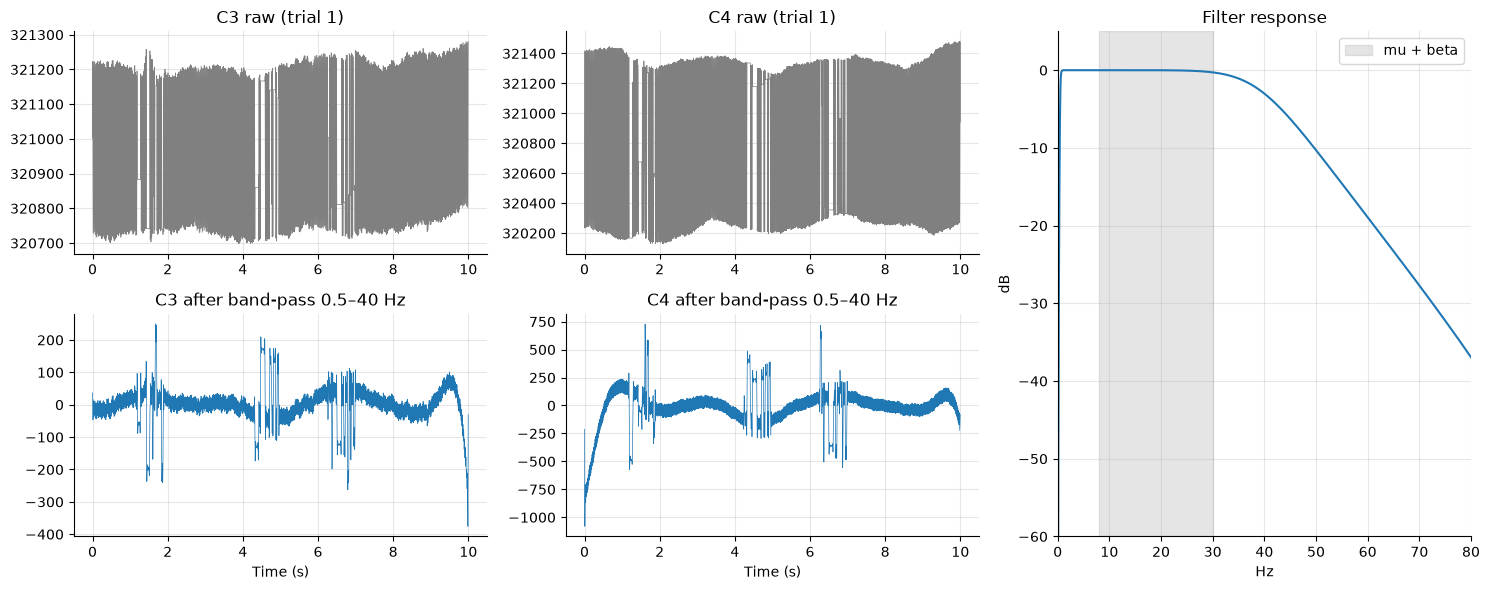

C3 trial 1 raw: mean 320,966, range 583
C3 trial 1 filtered: mean -1.75, range 625
Gain at 10 Hz (mu): -0.00 dB | at 50 Hz: -10.3 dB


In [4]:
X_bp = bp.bandpass(X_raw, *cfg["bandpass_hz"], FS)
t = np.arange(N) / FS

b, a = butter(4, cfg["bandpass_hz"], btype="bandpass", fs=FS)
w, h = freqz(b, a, worN=4096, fs=FS)

fig = plt.figure(figsize=(15, 6))
gs = fig.add_gridspec(2, 3)
for k, ch in enumerate([C3, C4]):
    a0 = fig.add_subplot(gs[0, k]); a0.plot(t, X_raw[0, ch], lw=0.5, color="grey"); a0.set_title(f"{CH[ch]} raw (trial 1)")
    a1 = fig.add_subplot(gs[1, k]); a1.plot(t, X_bp[0, ch], lw=0.5); a1.set_title(f"{CH[ch]} after band-pass 0.5–40 Hz"); a1.set_xlabel("Time (s)")
af = fig.add_subplot(gs[:, 2])
af.plot(w, 20 * np.log10(np.abs(h) + 1e-12)); af.set_ylim(-60, 5); af.set_xlim(0, 80)
af.axvspan(8, 30, color="grey", alpha=0.2, label="mu + beta")
af.set_title("Filter response"); af.set_xlabel("Hz"); af.set_ylabel("dB"); af.legend()
plt.tight_layout(); plt.show()

print(f"C3 trial 1 raw: mean {X_raw[0, C3].mean():,.0f}, range {np.ptp(X_raw[0, C3]):,.0f}")
print(f"C3 trial 1 filtered: mean {X_bp[0, C3].mean():.2f}, range {np.ptp(X_bp[0, C3]):,.0f}")
print("Gain at 10 Hz (mu): %.2f dB | at 50 Hz: %.1f dB" % tuple(20 * np.log10(np.abs(h[np.argmin(abs(w - f))])) for f in (10, 50)))

## Step 3: Notch filter (50 Hz)
**Task says:** *"Remove 50 Hz or 60 Hz power-line interference."*
- **Did:** Plotted the average spectrum on C3 to see **which** line frequency is in the data, then applied a notch at **50 Hz** (Q = 30, zero phase).
- **Why:** Mains power leaks into EEG. The plot decides between 50 and 60 Hz from the data instead of guessing.

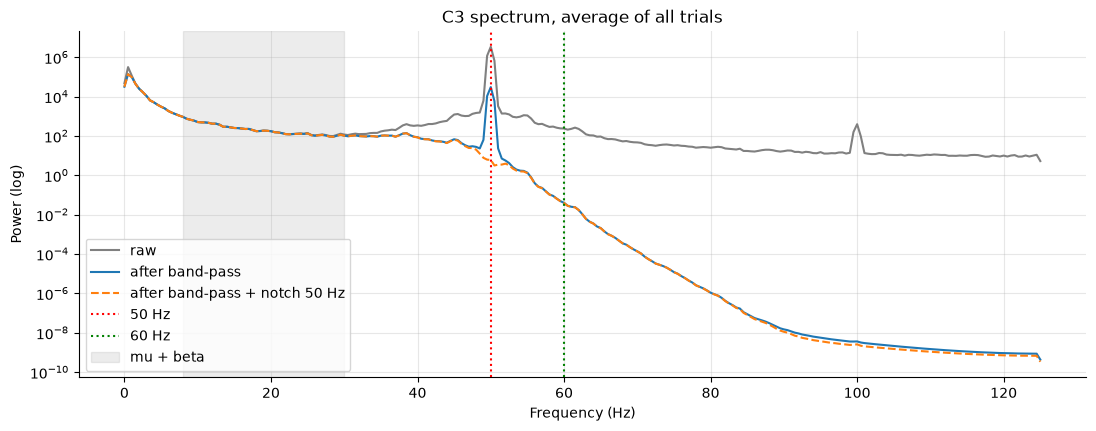

Power at 10 / 50 / 60 Hz (C3, mean of all trials):
                    10        50      60
raw                508  3.41e+06     238
band-pass          508  3.05e+04  0.0398
band-pass + notch  508      6.04  0.0392

50 Hz peak vs its neighbours (45 & 55 Hz) in raw: x2940
60 Hz peak vs its neighbours (55 & 65 Hz) in raw: x0.4


In [5]:
X_filt = bp.notch(X_bp, cfg["notch_hz"], FS, cfg["notch_q"])

def mean_psd(X, ch):
    f, p = welch(X[:, ch] - X[:, ch].mean(-1, keepdims=True), fs=FS, nperseg=2 * FS)
    return f, p.mean(0)

f, p_raw = mean_psd(X_raw, C3)
_, p_bp = mean_psd(X_bp, C3)
_, p_nt = mean_psd(X_filt, C3)
at = lambda p, hz: p[np.argmin(abs(f - hz))]

plt.figure(figsize=(13, 4.5))
plt.semilogy(f, p_raw, label="raw", color="grey")
plt.semilogy(f, p_bp, label="after band-pass")
plt.semilogy(f, p_nt, "--", label="after band-pass + notch 50 Hz")
plt.axvline(50, color="red", ls=":", label="50 Hz"); plt.axvline(60, color="green", ls=":", label="60 Hz")
plt.axvspan(8, 30, color="grey", alpha=0.15, label="mu + beta")
plt.xlabel("Frequency (Hz)"); plt.ylabel("Power (log)"); plt.title("C3 spectrum, average of all trials"); plt.legend()
plt.show()

tab = pd.DataFrame({hz: [at(p, hz) for p in (p_raw, p_bp, p_nt)] for hz in (10, 50, 60)},
                   index=["raw", "band-pass", "band-pass + notch"])
print("Power at 10 / 50 / 60 Hz (C3, mean of all trials):")
print(tab.map(lambda v: f"{v:.3g}"))
print(f"\n50 Hz peak vs its neighbours (45 & 55 Hz) in raw: x{at(p_raw, 50) / np.mean([at(p_raw, 45), at(p_raw, 55)]):.0f}")
print(f"60 Hz peak vs its neighbours (55 & 65 Hz) in raw: x{at(p_raw, 60) / np.mean([at(p_raw, 55), at(p_raw, 65)]):.1f}")
del X_bp

<!--N:s3_notch-->
**Noticed:** _to fill_

## Step 4: Artifact rejection
**Task says:** *"Drop trials/channels with extreme amplitude (eye blinks, muscle, electrode pops)."* and *"Document every rejected trial and the reason — this is part of scientific honesty."*
- **Did:** Three measures per trial (computed by `bp.artifact_measures`, the same function the demo app uses):
  1. **Peak-to-peak** (largest over channels) → blinks, electrode pops.
  2. **Standard deviation** (largest over channels) → muscle, long large slow waves.
  3. **Flat share** of the raw signal (samples that did not change) → disconnected electrode / device repeating values.

  The first and last 1 s are skipped (the filter bends them). Limits come from the data: **Q3 + 3 × IQR**, so only real outliers are removed. Flat limit = 10 %.
- **Why whole trials, not channels:** with only 4 channels, dropping one channel breaks the C3-vs-C4 comparison and the fixed input shape the models need, so a bad channel means a bad trial.

Limits: {'peak_to_peak': 8385.04, 'std': 809.16, 'flat_share': 0.1}
Removed: 269 of 2160 (12.5%)  -> saved outputs/removed_trials.csv
reason
flat                      94
peaks + too big           83
too big                   46
peaks + too big + flat    19
peaks                     16
too big + flat            11
Removal rate per class: {'LEFT': 0.124, 'RIGHT': 0.125}
Is rejection linked to the class? chi-square p = 0.97


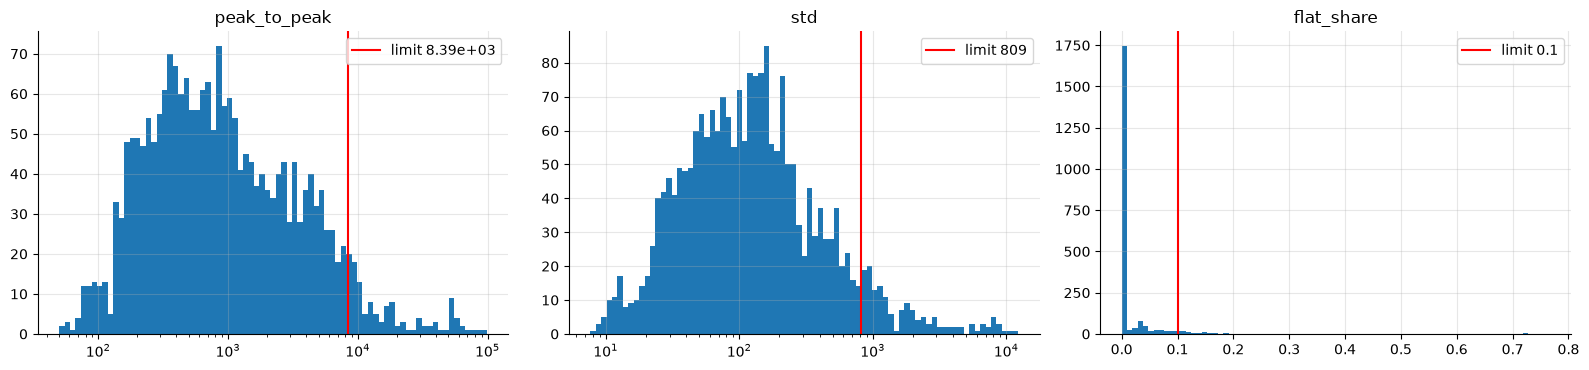

Kept: 1891 | {'LEFT': 948, 'RIGHT': 943}


In [6]:
m = bp.artifact_measures(X_raw, cfg)
def upper_limit(v, k=cfg["artifact"]["iqr_factor"]):
    q1, q3 = np.percentile(v, [25, 75]); return q3 + k * (q3 - q1)

limits = {"peak_to_peak": float(upper_limit(m["peak_to_peak"])),
          "std": float(upper_limit(m["std"])),
          "flat_share": cfg["artifact"]["flat_share_limit"]}
flags = pd.DataFrame({k: m[k] > limits[k] for k in limits})
bad = flags.any(axis=1).values
names = {"peak_to_peak": "peaks", "std": "too big", "flat_share": "flat"}
reason = flags.apply(lambda r: " + ".join(names[k] for k in limits if r[k]), axis=1)

removed = trials.loc[bad, ["filename", "label"]].copy()
removed["reason"] = reason[bad].values
for k in limits:
    removed[k] = np.round(m[k][bad], 3)
removed.to_csv(f"{OUT}/removed_trials.csv", index=False)

print("Limits:", {k: round(v, 2) for k, v in limits.items()})
print(f"Removed: {bad.sum()} of {len(bad)} ({bad.mean():.1%})  -> saved {OUT}/removed_trials.csv")
print(removed["reason"].value_counts().to_string())
rate = pd.Series(bad).groupby(y_all).mean()
print("Removal rate per class:", rate.round(3).to_dict())
chi = stats.chi2_contingency(pd.crosstab(y_all, bad))
print(f"Is rejection linked to the class? chi-square p = {chi.pvalue:.2f}")

fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
for a_, k in zip(ax, limits):
    v = m[k]
    bins = np.logspace(np.log10(v[v > 0].min()), np.log10(v.max()), 80) if k != "flat_share" else 80
    a_.hist(v, bins=bins); a_.axvline(limits[k], color="red", label=f"limit {limits[k]:.3g}")
    if k != "flat_share": a_.set_xscale("log")
    a_.set_title(k); a_.legend()
plt.tight_layout(); plt.show()

keep = ~bad
X_raw_k, X_filt_k = X_raw[keep], X_filt[keep]
trials_k = trials[keep].reset_index(drop=True)
y = y_all[keep]
print("Kept:", len(y), "|", pd.Series(y).value_counts().to_dict())

## Step 5: Re-referencing (Common Average Reference)
**Task says:** *"Common Average Reference (CAR) or Laplacian to reduce shared noise."*
- **Did:** CAR = at every time point, subtract the mean of the 4 channels from each channel. Measured the correlation between channels before and after, and plotted one trial.
- **Why:** Noise that reaches all electrodes equally (reference noise, far-away activity) cancels out.
- **Why we keep both versions:** with only **4** electrodes the "average" is not neutral: it contains C3 and C4 themselves, so part of C3 leaks into C4 and back. The config sets `use_car = false` for the main pipeline and keeps a CAR copy, so the models compare both (Stage 5). A real Laplacian needs neighbours around C3/C4, which this montage doesn't have.

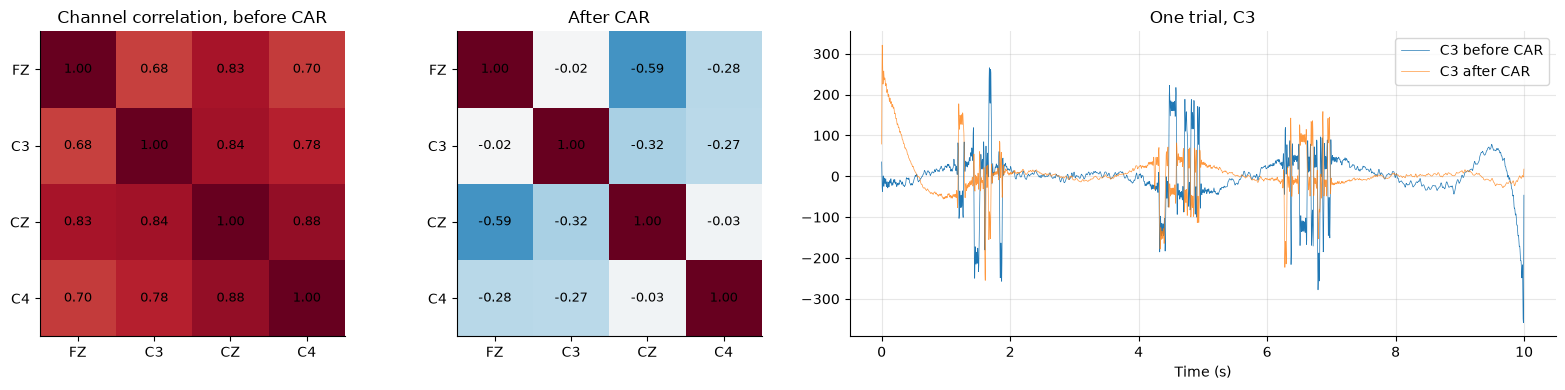

Mean correlation between channels: before 0.79 | after -0.25
C3–C4 correlation: before 0.78 | after -0.27
CAR copy differs from no-CAR copy: True


In [7]:
X_car_k = bp.car(X_filt_k)

def mean_corr(X, n=400):
    Z = X[:n, :, FS:-FS]
    return np.mean([np.corrcoef(z) for z in Z], axis=0)

cb, ca = mean_corr(X_filt_k), mean_corr(X_car_k)
fig, ax = plt.subplots(1, 3, figsize=(16, 4), gridspec_kw={"width_ratios": [1, 1, 2]})
for a_, c, ttl in [(ax[0], cb, "Channel correlation, before CAR"), (ax[1], ca, "After CAR")]:
    im = a_.imshow(c, vmin=-1, vmax=1, cmap="RdBu_r"); a_.set_xticks(range(4), CH); a_.set_yticks(range(4), CH)
    for i in range(4):
        for j in range(4):
            a_.text(j, i, f"{c[i, j]:.2f}", ha="center", va="center", fontsize=9)
    a_.set_title(ttl); a_.grid(False)
ax[2].plot(t, X_filt_k[0, C3], lw=0.5, label="C3 before CAR")
ax[2].plot(t, X_car_k[0, C3], lw=0.5, label="C3 after CAR", alpha=0.8)
ax[2].set_title("One trial, C3"); ax[2].set_xlabel("Time (s)"); ax[2].legend()
plt.tight_layout(); plt.show()

off = ~np.eye(4, dtype=bool)
print(f"Mean correlation between channels: before {cb[off].mean():.2f} | after {ca[off].mean():.2f}")
print(f"C3–C4 correlation: before {cb[C3, C4]:.2f} | after {ca[C3, C4]:.2f}")
print("CAR copy differs from no-CAR copy:", not np.allclose(X_car_k, X_filt_k))

## Step 6: Epoching
**Task says:** *"Cut the relevant time window after the cue (example: 0.5–3.5 s)."*
- **Problem:** the files have **no cue marker**, and each trial is 10 s. We cannot know where "after the cue" is from the file.
- **Did:** Looked for the window in the data: mu power (8–12 Hz) over time on C3 and C4, LEFT vs RIGHT, using **log + median** so a few spiky trials don't pull the curve. Then cut every trial to the chosen window.
- **Why:** Imagery should show as a mu **drop** (ERD) at a certain moment. The filter edges (first/last part) must also be removed, because `filtfilt` bends them.

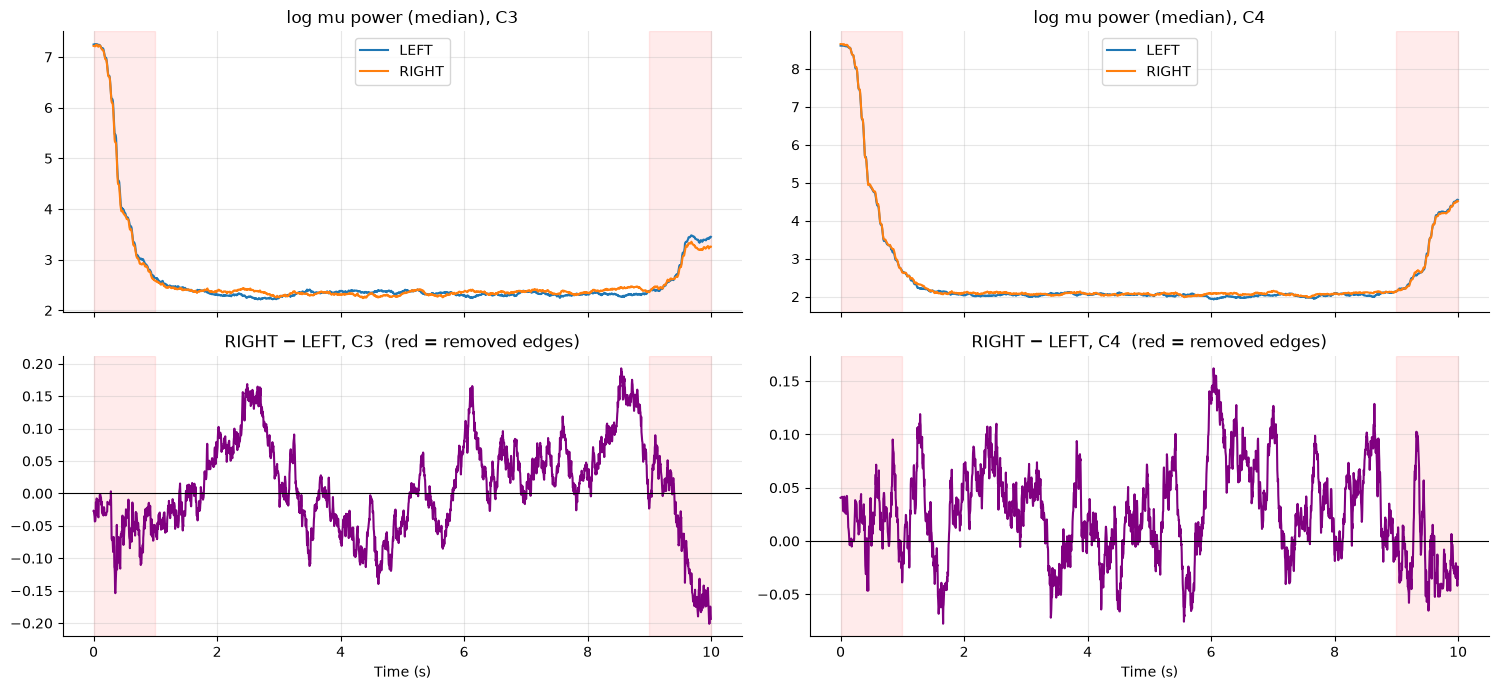

   0–0.5  s: log-mu +4.64 vs the 2–8 s level
 0.5–1    s: log-mu +1.19 vs the 2–8 s level
   1–2    s: log-mu +0.13 vs the 2–8 s level
   8–9    s: log-mu +0.03 vs the 2–8 s level
   9–9.5  s: log-mu +0.30 vs the 2–8 s level
 9.5–10   s: log-mu +1.52 vs the 2–8 s level

Epoch window: [1.0, 9.0] s -> (1891, 4, 2000) (trials, channels, samples)


In [8]:
mu = bp.bandpass(X_filt_k[:, [C3, C4]], 8, 12, FS) ** 2
mu = uniform_filter1d(mu, size=int(0.5 * FS), axis=-1)
log_mu = np.log(mu + 1e-12)

fig, ax = plt.subplots(2, 2, figsize=(15, 7), sharex=True)
for k, name in enumerate(["C3", "C4"]):
    med = {lab: np.median(log_mu[y == lab, k], axis=0) for lab in ("LEFT", "RIGHT")}
    for lab in med:
        ax[0, k].plot(t, med[lab], color=COL[lab], label=lab)
    ax[1, k].plot(t, med["RIGHT"] - med["LEFT"], color="purple")
    ax[1, k].axhline(0, color="black", lw=0.8)
    for a_ in ax[:, k]:
        a_.axvspan(0, cfg["epoch_seconds"][0], color="red", alpha=0.08)
        a_.axvspan(cfg["epoch_seconds"][1], 10, color="red", alpha=0.08)
    ax[0, k].set_title(f"log mu power (median), {name}"); ax[0, k].legend()
    ax[1, k].set_title(f"RIGHT − LEFT, {name}  (red = removed edges)"); ax[1, k].set_xlabel("Time (s)")
plt.tight_layout(); plt.show()

whole = np.median(log_mu, axis=(0, 1))
mid = whole[(t > 2) & (t < 8)].mean()
for lo_, hi_ in [(0, 0.5), (0.5, 1), (1, 2), (8, 9), (9, 9.5), (9.5, 10)]:
    seg = whole[(t >= lo_) & (t < hi_)].mean()
    print(f"{lo_:>4}–{hi_:<4} s: log-mu {seg - mid:+.2f} vs the 2–8 s level")

X_ep_nocar = bp.cut_epoch(X_filt_k, cfg)
X_ep_car = bp.cut_epoch(X_car_k, cfg)
print("\nEpoch window:", cfg["epoch_seconds"], "s ->", X_ep_nocar.shape, "(trials, channels, samples)")

<!--N:s6_epoch-->
**Noticed:** _to fill_

## Step 7: Baseline correction
**Task says:** *"Subtract pre-stimulus mean so signals are centered."*
- **Did:** There is **no pre-stimulus (rest) period**: Step 6 showed the trials are back-to-back with no cue. The closest correct version is to subtract each epoch's **own mean** per channel, so every epoch is centered on 0.
- **Why:** Cutting 1–9 s from a filtered signal can leave a small offset (slow leftovers). Centering removes it without changing the shape, so mu/beta power stays the same.

Epoch mean, before: median |mean| 2.85, max |mean| 175.58
Epoch mean, after:  max |mean| 4.4e-14


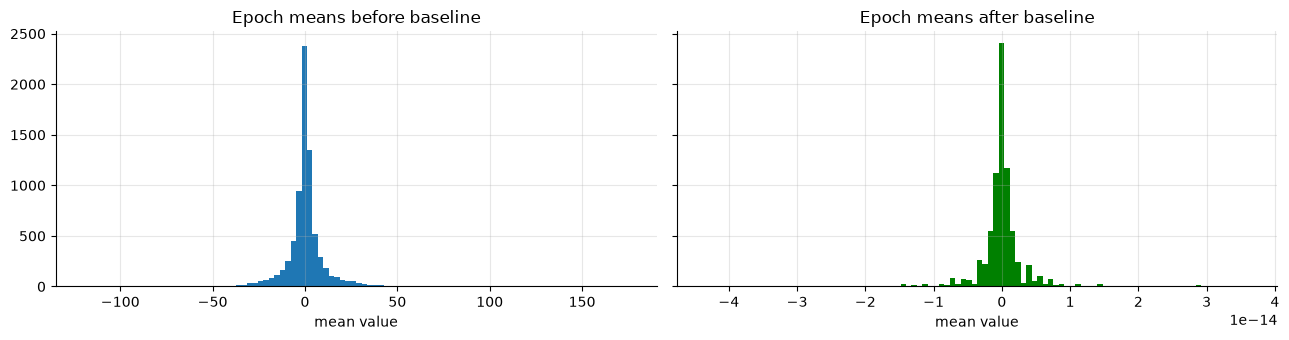

In [9]:
means_before = X_ep_nocar.mean(-1)
X_ep_nocar = bp.baseline(X_ep_nocar)
X_ep_car = bp.baseline(X_ep_car)
means_after = X_ep_nocar.mean(-1)

print(f"Epoch mean, before: median |mean| {np.median(abs(means_before)):.2f}, max |mean| {abs(means_before).max():.2f}")
print(f"Epoch mean, after:  max |mean| {abs(means_after).max():.1e}")

fig, ax = plt.subplots(1, 2, figsize=(13, 3.5), sharey=True)
ax[0].hist(means_before.ravel(), bins=100); ax[0].set_title("Epoch means before baseline")
ax[1].hist(means_after.ravel(), bins=100, color="green"); ax[1].set_title("Epoch means after baseline")
for a_ in ax: a_.set_xlabel("mean value")
plt.tight_layout(); plt.show()

## Step 8: Normalization (for deep learning)
**Task says:** *"Optional channel-wise or global scaling (helpful for deep learning)."*
- **Did:** Channel-wise z-score (every channel of every epoch → mean 0, std 1). It is applied **only to the deep-learning input** (inside `bp.dl_input`).
- **Why:** Trial sizes differ a lot. Deep nets learn better when every input has the same scale. **CSP + SVM is not normalized** on purpose: CSP works on signal power (variance), and scaling each channel to std 1 would erase exactly the power change (the ERD) it looks for.

Std before: min 5.3, median 48.8, max 765.3  (max/min = x143)
Std after:  min 1.000, max 1.000


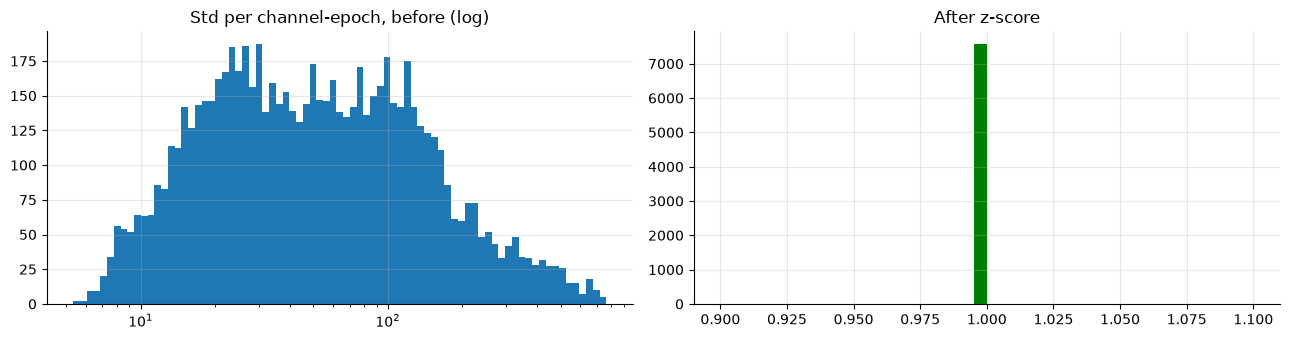

In [10]:
X_norm_demo = bp.zscore(X_ep_nocar)
sd_b, sd_a = X_ep_nocar.std(-1).ravel(), X_norm_demo.std(-1).ravel()
print(f"Std before: min {sd_b.min():.1f}, median {np.median(sd_b):.1f}, max {sd_b.max():.1f}  (max/min = x{sd_b.max() / sd_b.min():.0f})")
print(f"Std after:  min {sd_a.min():.3f}, max {sd_a.max():.3f}")

fig, ax = plt.subplots(1, 2, figsize=(13, 3.5))
ax[0].hist(sd_b, bins=np.logspace(np.log10(sd_b.min()), np.log10(sd_b.max()), 80)); ax[0].set_xscale("log")
ax[0].set_title("Std per channel-epoch, before (log)")
ax[1].hist(sd_a, bins=40, range=(0.9, 1.1), color="green"); ax[1].set_title("After z-score")
plt.tight_layout(); plt.show()
del X_norm_demo

## Save the clean epoched arrays (Stage 2 deliverable)
**Task deliverable:** *"Clean epoched arrays (.npy / .pkl)."*
- **Did:** Saved both versions (no CAR = main, CAR = comparison), the labels and the trial table. Then checked that the **shared** function `bp.preprocess()` (used by the demo app) gives exactly the same result as the step-by-step cells above.
- **Why:** The task says *"Keep preprocessing code identical between training and inference."* This check proves it.

In [11]:
np.save(f"{OUT}/epochs_noCAR.npy", X_ep_nocar.astype(np.float32))
np.save(f"{OUT}/epochs_CAR.npy", X_ep_car.astype(np.float32))
np.save(f"{OUT}/labels.npy", y)
trials_k.drop(columns=["path"]).to_csv(f"{OUT}/trials_kept.csv", index=False)

same_nocar = np.allclose(bp.preprocess(X_raw_k[:100], cfg, use_car=False), X_ep_nocar[:100])
same_car = np.allclose(bp.preprocess(X_raw_k[:100], cfg, use_car=True), X_ep_car[:100])
print("bp.preprocess() == step-by-step (no CAR):", same_nocar)
print("bp.preprocess() == step-by-step (CAR):   ", same_car)
for f_ in ["epochs_noCAR.npy", "epochs_CAR.npy", "labels.npy", "trials_kept.csv", "removed_trials.csv", "label_map.csv"]:
    print(f"  {OUT}/{f_:22s} {os.path.getsize(f'{OUT}/{f_}') / 1e6:7.1f} MB")

bp.preprocess() == step-by-step (no CAR): True
bp.preprocess() == step-by-step (CAR):    True
  outputs/epochs_noCAR.npy          60.5 MB
  outputs/epochs_CAR.npy            60.5 MB
  outputs/labels.npy                 0.0 MB
  outputs/trials_kept.csv            0.3 MB
  outputs/removed_trials.csv         0.0 MB
  outputs/label_map.csv              0.1 MB


# Stage 3 — Exploratory Data Analysis (EDA)
**Task says:** *"EDA answers the questions that decide whether the data is usable and which models are likely to work."*

## 3.1 Must-do checks
**Task says:**
- *Class balance: How many LEFT vs RIGHT trials? (aim for roughly equal)*
- *Sampling rate & trial length consistency across the files*
- *Missing values, NaNs, flat channels, extreme outliers*
- *Percentage of trials rejected by artifact rules (document it!)*

,Result
Check,
Class balance (all files),LEFT 1082 / RIGHT 1078 (RIGHT share 49.9%)
Class balance (after rejection),LEFT 948 / RIGHT 943 (RIGHT share 49.9%)
Sampling rate,217.69–286.13 Hz in every file → 250 Hz
Trial length,[2500] rows = 10.0 s in every file
Channel names,"['FZ,C3,CZ,C4'] in every file"
Missing values / NaN,0 files
Flat channels (>10% repeated values),"FZ: 124, C3: 124, CZ: 124, C4: 124 trials"
Extreme outliers (peaks / too big),118 / 159 trials
Rejected by artifact rules,"269 of 2160 = 12.5% (LEFT 134, RIGHT 135) → removed_trials.csv"


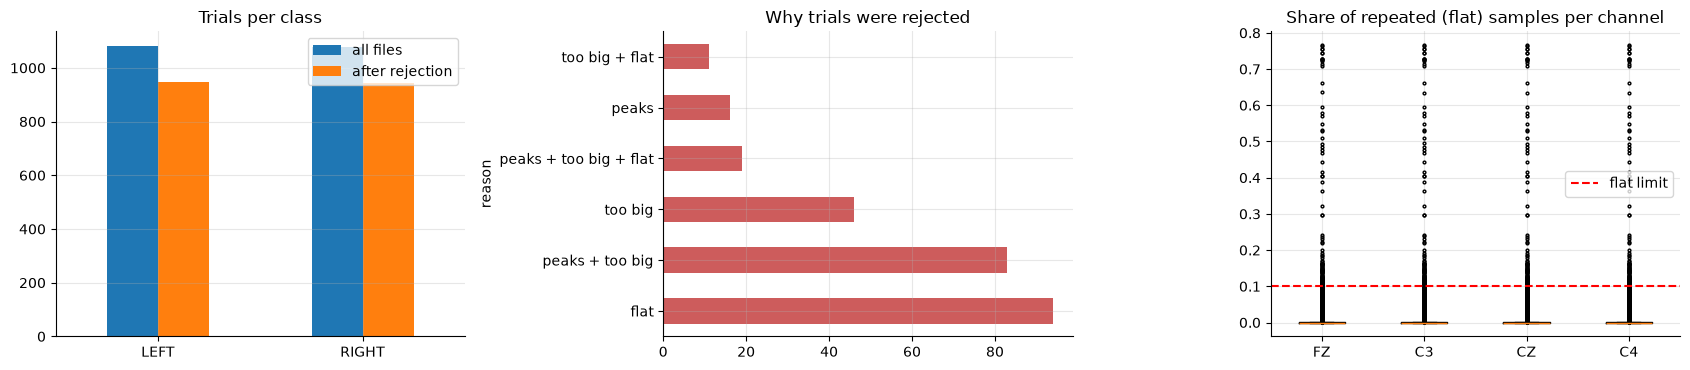

In [12]:
before, after = pd.Series(y_all).value_counts(), pd.Series(y).value_counts()
flat_ch = (np.diff(X_raw, axis=-1) == 0).mean(-1)            # (trials, channels)
flat_per_ch = pd.Series((flat_ch > cfg["artifact"]["flat_share_limit"]).sum(0), index=CH)

checks = pd.DataFrame([
    ["Class balance (all files)", f"LEFT {before['LEFT']} / RIGHT {before['RIGHT']}  (RIGHT share {before['RIGHT'] / before.sum():.1%})"],
    ["Class balance (after rejection)", f"LEFT {after['LEFT']} / RIGHT {after['RIGHT']}  (RIGHT share {after['RIGHT'] / after.sum():.1%})"],
    ["Sampling rate", f"{trials['rate_hz'].min():.2f}–{trials['rate_hz'].max():.2f} Hz in every file → {FS} Hz"],
    ["Trial length", f"{trials['rows'].unique().tolist()} rows = {trials['duration_s'].median():.1f} s in every file"],
    ["Channel names", f"{trials['channels'].unique().tolist()} in every file"],
    ["Missing values / NaN", f"{int(trials['has_nan'].sum())} files"],
    ["Flat channels (>10% repeated values)", ", ".join(f"{c}: {n}" for c, n in flat_per_ch.items()) + " trials"],
    ["Extreme outliers (peaks / too big)", f"{int(flags['peak_to_peak'].sum())} / {int(flags['std'].sum())} trials"],
    ["Rejected by artifact rules", f"{bad.sum()} of {len(bad)} = {bad.mean():.1%}  (LEFT {int(removed['label'].eq('LEFT').sum())}, RIGHT {int(removed['label'].eq('RIGHT').sum())}) → removed_trials.csv"],
], columns=["Check", "Result"])
pd.set_option("display.max_colwidth", None)
display(checks.set_index("Check"))

fig, ax = plt.subplots(1, 3, figsize=(17, 3.8))
pd.DataFrame({"all files": before, "after rejection": after}).plot(kind="bar", ax=ax[0], rot=0)
ax[0].set_title("Trials per class")
removed["reason"].value_counts().plot(kind="barh", ax=ax[1], color="indianred"); ax[1].set_title("Why trials were rejected")
ax[2].boxplot([flat_ch[:, i] for i in range(4)], tick_labels=CH, showfliers=True, flierprops={"markersize": 2})
ax[2].axhline(cfg["artifact"]["flat_share_limit"], color="red", ls="--", label="flat limit"); ax[2].legend()
ax[2].set_title("Share of repeated (flat) samples per channel")
plt.tight_layout(); plt.show()

<!--N:e31-->
**Noticed:** _to fill_

## 3.2 Visualizations that give insight
### 3.2.1 Time-domain plots of a few LEFT and RIGHT trials on C3 and C4 (raw + filtered)
**Task says:** *"Time-domain plots of a few LEFT and RIGHT trials on C3 and C4 (raw + filtered)."*
- **Did:** 3 LEFT + 3 RIGHT kept trials (random, fixed seed). Raw (offset removed) on the left, filtered (0.5–40 Hz + notch) on the right, for C3 and C4.
- **Why:** To see what the signal looks like, how much the filtering changes it, and whether LEFT and RIGHT can be told apart by eye.

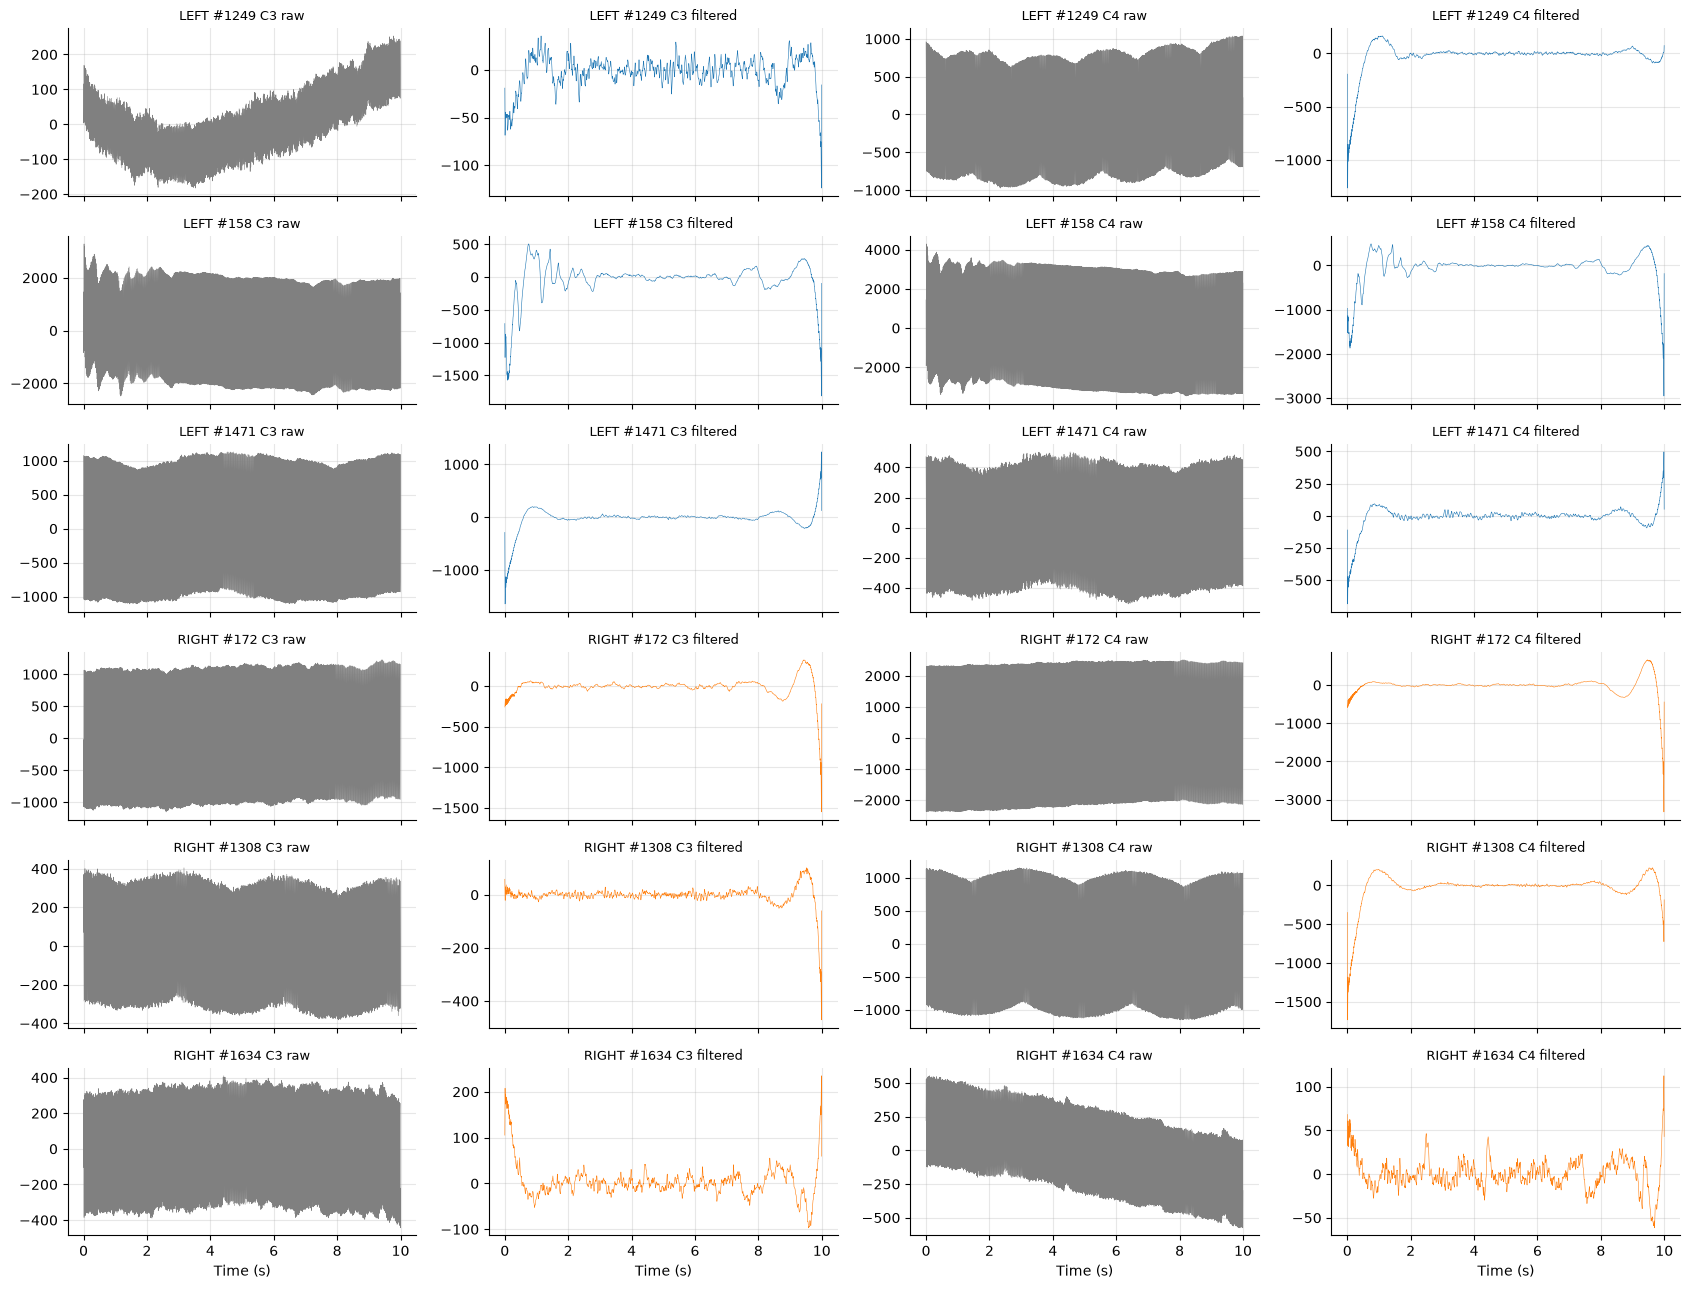

Median peak-to-peak on C3/C4: raw 1,586 | filtered (1–9 s) 197 | ratio x8


In [13]:
rng = np.random.default_rng(SEED)
pick = [(i, "LEFT") for i in rng.choice(np.where(y == "LEFT")[0], 3, replace=False)] + \
       [(i, "RIGHT") for i in rng.choice(np.where(y == "RIGHT")[0], 3, replace=False)]
fig, ax = plt.subplots(6, 4, figsize=(17, 13), sharex=True)
for r, (i, lab) in enumerate(pick):
    for c, ch in enumerate([C3, C4]):
        raw = X_raw_k[i, ch] - X_raw_k[i, ch].mean()
        ax[r, 2 * c].plot(t, raw, lw=0.4, color="grey")
        ax[r, 2 * c].set_title(f"{lab} #{i} {CH[ch]} raw", fontsize=9)
        ax[r, 2 * c + 1].plot(t, X_filt_k[i, ch], lw=0.4, color=COL[lab])
        ax[r, 2 * c + 1].set_title(f"{lab} #{i} {CH[ch]} filtered", fontsize=9)
for a_ in ax[-1]: a_.set_xlabel("Time (s)")
plt.tight_layout(); plt.show()

amp_raw = np.median([np.ptp(X_raw_k[i, [C3, C4]], axis=-1).mean() for i, _ in pick])
amp_f = np.median([np.ptp(X_filt_k[i, [C3, C4], FS:-FS], axis=-1).mean() for i, _ in pick])
print(f"Median peak-to-peak on C3/C4: raw {amp_raw:,.0f} | filtered (1–9 s) {amp_f:,.0f} | ratio x{amp_raw / amp_f:.0f}")

<!--N:e321-->
**Noticed:** _to fill_

### 3.2.2 Average Power Spectral Density (PSD) for LEFT vs RIGHT on C3 and C4
**Task says:** *"Average Power Spectral Density (PSD) for LEFT vs RIGHT on C3 and C4."* This plot is the one that decides the 3.3 rule.
- **Did:** Welch PSD (2 s windows) of every epoch. Mean of log-power per class with a 95 % confidence band, for C3 and C4, without and with CAR. Then the RIGHT − LEFT difference with its 95 % band and a t-test in mu and beta.
- **Expected if motor imagery is present:** imagining RIGHT lowers mu/beta on **C3** (left brain); imagining LEFT lowers it on **C4**. So on C3, RIGHT < LEFT, and on C4, LEFT < RIGHT.

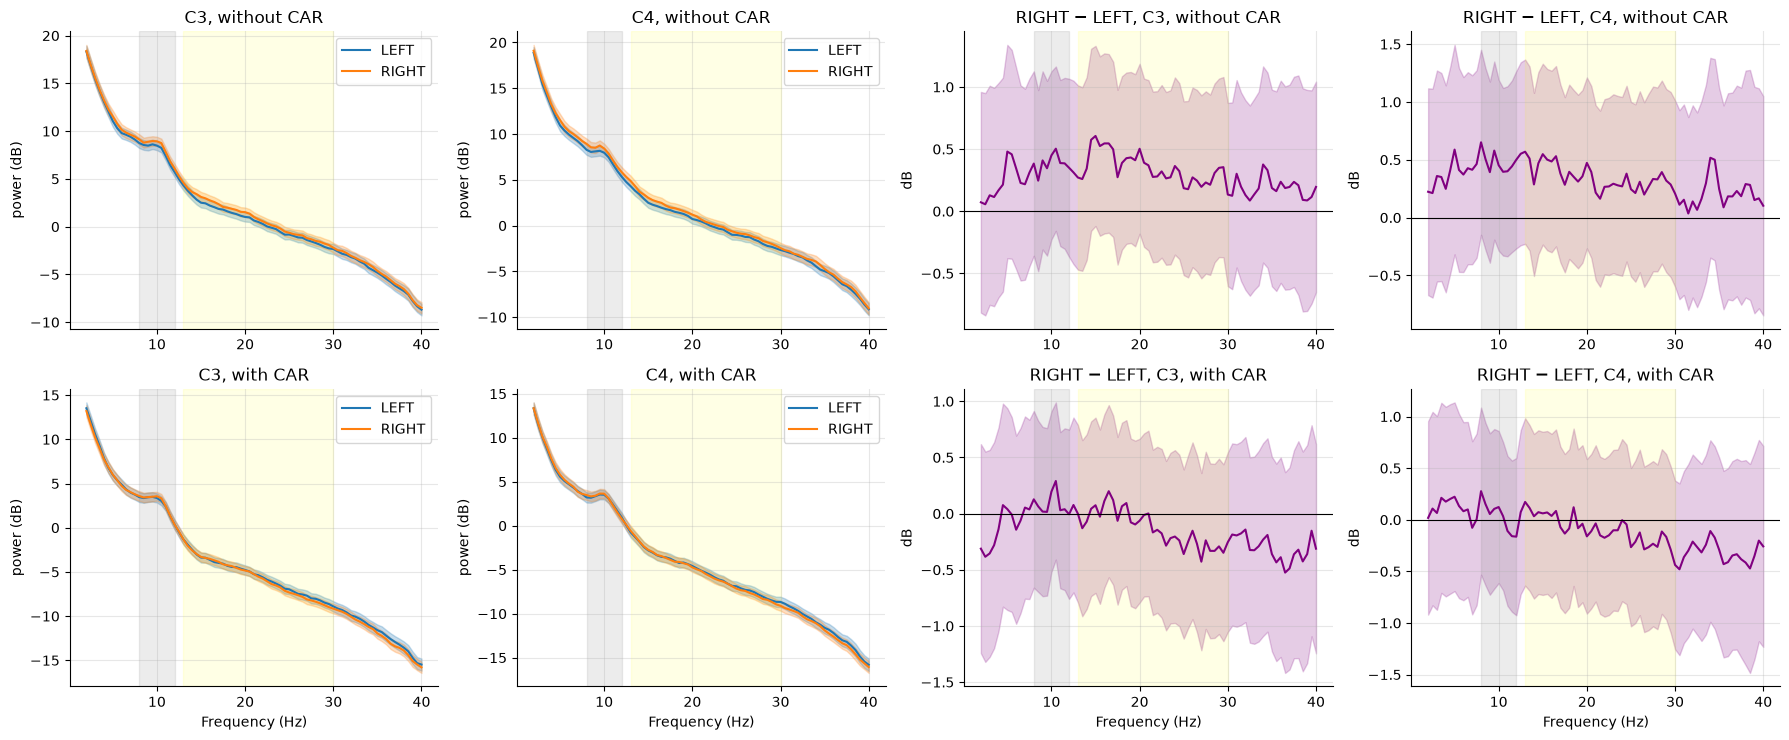

,version,channel,band,RIGHT − LEFT (dB),t-test p,expected sign,matches expected
0,without CAR,C3,mu 8–12,0.384,0.255,−,False
1,without CAR,C3,beta 13–30,0.347,0.315,−,False
2,without CAR,C4,mu 8–12,0.481,0.195,+,True
3,without CAR,C4,beta 13–30,0.346,0.359,+,True
4,with CAR,C3,mu 8–12,0.086,0.807,−,False
5,with CAR,C3,beta 13–30,-0.129,0.730,−,True
6,with CAR,C4,mu 8–12,0.036,0.923,+,True
7,with CAR,C4,beta 13–30,-0.095,0.804,+,False


In [14]:
f, P_nocar = welch(X_ep_nocar, fs=FS, nperseg=2 * FS, axis=-1)
_, P_car = welch(X_ep_car, fs=FS, nperseg=2 * FS, axis=-1)
LOGP = {"without CAR": 10 * np.log10(P_nocar), "with CAR": 10 * np.log10(P_car)}
fb = (f >= 2) & (f <= 40)
BANDS = {"mu 8–12": (8, 12), "beta 13–30": (13, 30)}

fig, ax = plt.subplots(2, 4, figsize=(18, 7.5))
rows_ = []
for r, (vname, L) in enumerate(LOGP.items()):
    for c, ch in enumerate([C3, C4]):
        a_ = ax[r, c]
        for lab in ("LEFT", "RIGHT"):
            v = L[y == lab, ch][:, fb]; mu_, se = v.mean(0), v.std(0) / np.sqrt(len(v))
            a_.plot(f[fb], mu_, color=COL[lab], label=lab); a_.fill_between(f[fb], mu_ - 1.96 * se, mu_ + 1.96 * se, color=COL[lab], alpha=0.25)
        a_.axvspan(8, 12, color="grey", alpha=0.15); a_.axvspan(13, 30, color="yellow", alpha=0.1)
        a_.set_title(f"{CH[ch]}, {vname}"); a_.set_ylabel("power (dB)"); a_.legend()
        # difference RIGHT - LEFT
        d_ = ax[r, c + 2]
        lv, rv = L[y == "LEFT", ch][:, fb], L[y == "RIGHT", ch][:, fb]
        diff = rv.mean(0) - lv.mean(0); se = np.sqrt(lv.var(0) / len(lv) + rv.var(0) / len(rv))
        d_.plot(f[fb], diff, color="purple"); d_.fill_between(f[fb], diff - 1.96 * se, diff + 1.96 * se, color="purple", alpha=0.2)
        d_.axhline(0, color="black", lw=0.8); d_.axvspan(8, 12, color="grey", alpha=0.15); d_.axvspan(13, 30, color="yellow", alpha=0.1)
        d_.set_title(f"RIGHT − LEFT, {CH[ch]}, {vname}"); d_.set_ylabel("dB")
        for bname, (lo_, hi_) in BANDS.items():
            sel = (f >= lo_) & (f <= hi_)
            lb, rb = L[y == "LEFT", ch][:, sel].mean(1), L[y == "RIGHT", ch][:, sel].mean(1)
            rows_.append({"version": vname, "channel": CH[ch], "band": bname,
                          "RIGHT − LEFT (dB)": rb.mean() - lb.mean(), "t-test p": stats.ttest_ind(rb, lb).pvalue,
                          "expected sign": "−" if ch == C3 else "+"})
for a_ in ax[-1]: a_.set_xlabel("Frequency (Hz)")
plt.tight_layout(); plt.show()
psd_tab = pd.DataFrame(rows_)
psd_tab["matches expected"] = np.where(psd_tab["expected sign"] == "−", psd_tab["RIGHT − LEFT (dB)"] < 0, psd_tab["RIGHT − LEFT (dB)"] > 0)
psd_tab.round(3)

<!--N:e322-->
**Noticed:** _to fill_

### 3.2.3 Event-Related Desynchronization (ERD) over the contralateral motor cortex
**Task says:** *"Look for ERD: power decrease in mu/beta over the contralateral motor cortex."*
- **Did:** One number per trial, the **lateralization index** `LI = (C4 − C3) / (C4 + C3)` of band power. Contralateral ERD means: LEFT imagery → C4 drops → LI **lower**; RIGHT imagery → C3 drops → LI **higher**. So we expect LI(LEFT) < LI(RIGHT).
  Effect size = Cohen's d (0.2 small, 0.5 medium, 0.8 large), plus a Mann-Whitney test.
- **Why this way:** the classic ERD% needs a rest period before the cue to compare with. The data has none (Step 6–7), so we compare the two hemispheres inside each trial instead.

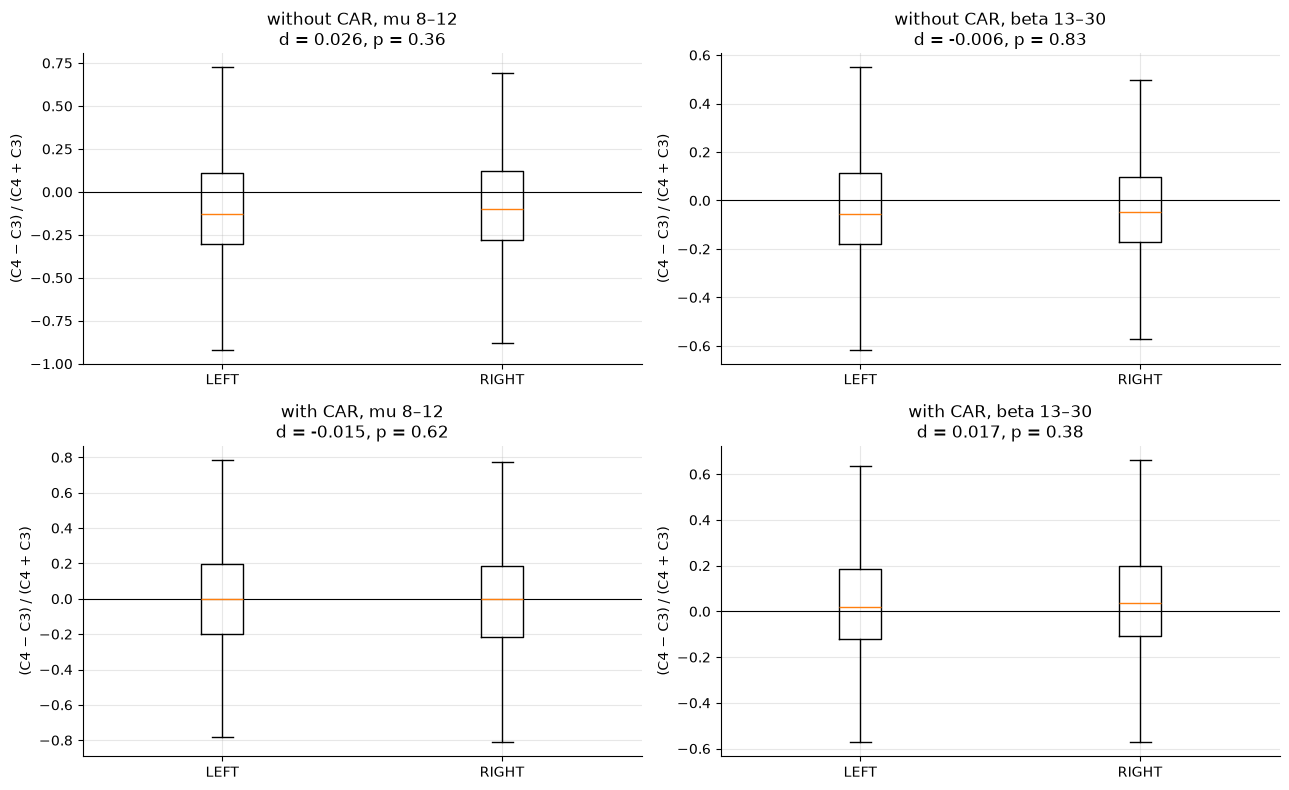

,version,band,median LI LEFT,median LI RIGHT,Cohen d (RIGHT−LEFT),Mann-Whitney p,expected
0,without CAR,mu 8–12,-0.131,-0.101,0.026,0.356,d > 0
1,without CAR,beta 13–30,-0.058,-0.048,-0.006,0.825,d > 0
2,with CAR,mu 8–12,-0.000,-0.002,-0.015,0.620,d > 0
3,with CAR,beta 13–30,0.018,0.035,0.017,0.383,d > 0


In [15]:
def cohen_d(a, b):
    return (b.mean() - a.mean()) / np.sqrt((a.var(ddof=1) + b.var(ddof=1)) / 2)

def band_power(P, lo_, hi_):
    return P[..., (f >= lo_) & (f <= hi_)].mean(-1)

PS = {"without CAR": P_nocar, "with CAR": P_car}
fig, ax = plt.subplots(2, 2, figsize=(13, 8))
erd_rows = []
for r, (vname, P) in enumerate(PS.items()):
    for c, (bname, (lo_, hi_)) in enumerate(BANDS.items()):
        bpw = band_power(P, lo_, hi_)
        li = (bpw[:, C4] - bpw[:, C3]) / (bpw[:, C4] + bpw[:, C3])
        l_, r_ = li[y == "LEFT"], li[y == "RIGHT"]
        d = cohen_d(l_, r_); p = stats.mannwhitneyu(l_, r_).pvalue
        erd_rows.append({"version": vname, "band": bname, "median LI LEFT": np.median(l_), "median LI RIGHT": np.median(r_),
                         "Cohen d (RIGHT−LEFT)": d, "Mann-Whitney p": p, "expected": "d > 0"})
        ax[r, c].boxplot([l_, r_], tick_labels=["LEFT", "RIGHT"], showfliers=False)
        ax[r, c].axhline(0, color="black", lw=0.8)
        ax[r, c].set_title(f"{vname}, {bname}\nd = {d:.3f}, p = {p:.2f}"); ax[r, c].set_ylabel("(C4 − C3) / (C4 + C3)")
plt.tight_layout(); plt.show()
erd_tab = pd.DataFrame(erd_rows); erd_tab.round(3)

<!--N:e323-->
**Noticed:** _to fill_

### 3.2.4 Simple band-power comparison per channel
**Task says:** *"Simple band-power comparison per channel (already hints which electrodes are informative)."*
- **Did:** Log band power per channel, LEFT vs RIGHT, and the effect size (Cohen's d) for every channel × band × version, shown as a heat-map.
- **Why:** The channel with the largest |d| is the most informative one. If motor imagery is present, C3 and C4 should stand out, with opposite signs.

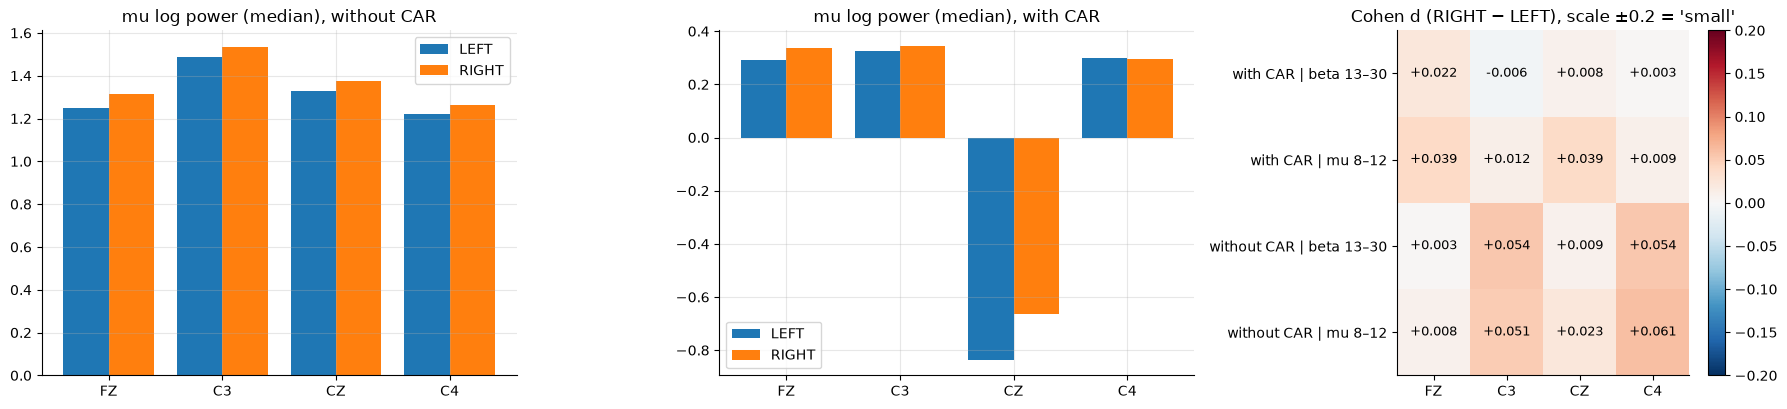

channel                    FZ     C3     CZ     C4
version     band                                  
with CAR    beta 13–30  0.022 -0.006  0.008  0.003
            mu 8–12     0.039  0.012  0.039  0.009
without CAR beta 13–30  0.003  0.054  0.009  0.054
            mu 8–12     0.008  0.051  0.023  0.061

In [16]:
bp_rows = []
fig, ax = plt.subplots(1, 3, figsize=(18, 4.2), gridspec_kw={"width_ratios": [1.3, 1.3, 1]})
for k, (vname, P) in enumerate(PS.items()):
    for bname, (lo_, hi_) in BANDS.items():
        lp = np.log(band_power(P, lo_, hi_))
        for ch in range(4):
            bp_rows.append({"version": vname, "band": bname, "channel": CH[ch],
                            "d": cohen_d(lp[y == "LEFT", ch], lp[y == "RIGHT", ch])})
    lp = np.log(band_power(P, 8, 12))
    x_ = np.arange(4)
    ax[k].bar(x_ - 0.2, np.median(lp[y == "LEFT"], 0), 0.4, color=COL["LEFT"], label="LEFT")
    ax[k].bar(x_ + 0.2, np.median(lp[y == "RIGHT"], 0), 0.4, color=COL["RIGHT"], label="RIGHT")
    ax[k].set_xticks(x_, CH); ax[k].set_title(f"mu log power (median), {vname}"); ax[k].legend()
bp_tab = pd.DataFrame(bp_rows)
heat = bp_tab.pivot_table(index=["version", "band"], columns="channel", values="d")[CH]
im = ax[2].imshow(heat.values, cmap="RdBu_r", vmin=-0.2, vmax=0.2, aspect="auto")
ax[2].set_xticks(range(4), CH); ax[2].set_yticks(range(len(heat)), [f"{v} | {b}" for v, b in heat.index]); ax[2].grid(False)
for i in range(heat.shape[0]):
    for j in range(4):
        ax[2].text(j, i, f"{heat.values[i, j]:+.3f}", ha="center", va="center", fontsize=9)
ax[2].set_title("Cohen d (RIGHT − LEFT), scale ±0.2 = 'small'"); plt.colorbar(im, ax=ax[2])
plt.tight_layout(); plt.show()
heat.round(3)

## 3.3 Why EDA matters — apply the task's decision rule
**Task says:** *"If the PSD already shows a clear LEFT–RIGHT difference in the mu/beta range on C3/C4, then classical methods (CSP + SVM) and deep models both have a good chance. If no difference appears, **go back to processing or data quality** before modeling."*
- **Did:** Turned the rule into numbers: the largest effect from 3.2.2–3.2.4, and whether C3 and C4 move in the expected opposite directions. A "clear" difference needs at least a small effect (|d| ≥ 0.2).

In [17]:
all_d = pd.concat([erd_tab["Cohen d (RIGHT−LEFT)"], bp_tab["d"]]).abs()
pattern_ok = psd_tab.query("version == 'without CAR'")["matches expected"].mean()
print(f"Largest |effect size| in 3.2.3–3.2.4: {all_d.max():.3f}   (0.2 = small)")
print(f"PSD differences with the expected sign (C3: RIGHT<LEFT, C4: LEFT<RIGHT), no CAR: {pattern_ok:.0%}")
print(f"PSD differences that are significant (p<0.05): {(psd_tab['t-test p'] < 0.05).sum()} of {len(psd_tab)}")
clear = all_d.max() >= 0.2 and pattern_ok == 1
print("\nDECISION (task rule 3.3):", "CLEAR LEFT/RIGHT difference → go to modeling" if clear
      else "NO clear LEFT/RIGHT difference → go back to data quality (3.4) before modeling")

Largest |effect size| in 3.2.3–3.2.4: 0.061   (0.2 = small)
PSD differences with the expected sign (C3: RIGHT<LEFT, C4: LEFT<RIGHT), no CAR: 50%
PSD differences that are significant (p<0.05): 0 of 8

DECISION (task rule 3.3): NO clear LEFT/RIGHT difference → go back to data quality (3.4) before modeling


<!--N:e33-->
**Noticed:** _to fill_

## 3.4 Extra questions about the data (data quality)
The 3.3 rule says to **go back to processing or data quality** when no difference appears. Processing was already checked step by step (Stage 2), so these extra questions check the **data quality** itself:

| # | Question | Why we ask it |
|---|---|---|
| 3.4.1 | How many recording sessions are there, and are the trials back-to-back? | The task says *"use subject-aware CV so the model is not tested on the same person's data it was trained on"*. Sessions are the closest thing to subjects we have. |
| 3.4.2 | Are there duplicated trial files? Do copies have the same label? | A copy with a different label means a wrong label. Copies in train **and** test also leak. |
| 3.4.3 | Is the label order shifted? (2400 labels for 2160 files) | If labels were just shifted, a shift would make all copies agree. |
| 3.4.4 | Do the sessions differ more than LEFT vs RIGHT? | A strong session effect hides the class effect and makes session-aware CV necessary. |
| 3.4.5 | Is the ERD clearer late in the trial (4–9 s)? | Step 6 hinted the difference may be clearest late. |

### 3.4.1 Recording sessions
- **Did:** Used the real clock time (`Time` column) of the first and last sample of every file. Sorted trials by start time; a gap of more than 60 s starts a new session.

Sessions: 80 over 19.4 days
Trials per session: {9: 41, 18: 5, 27: 6, 36: 10, 45: 2, 54: 3, 63: 6, 72: 4, 81: 1, 90: 2}
Every session is a multiple of 9 trials: True
Gap between trials inside a session: median 0.00 s
File order vs recording order (Spearman rho): -0.19
Sessions with both classes: 80 of 80


C:\Users\esraa\AppData\Local\Temp\ipykernel_24520\2651898505.py:16: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  print("Sessions with both classes:", int(((per_s > 0).sum(1) == 2).sum()), "of", len(per_s))


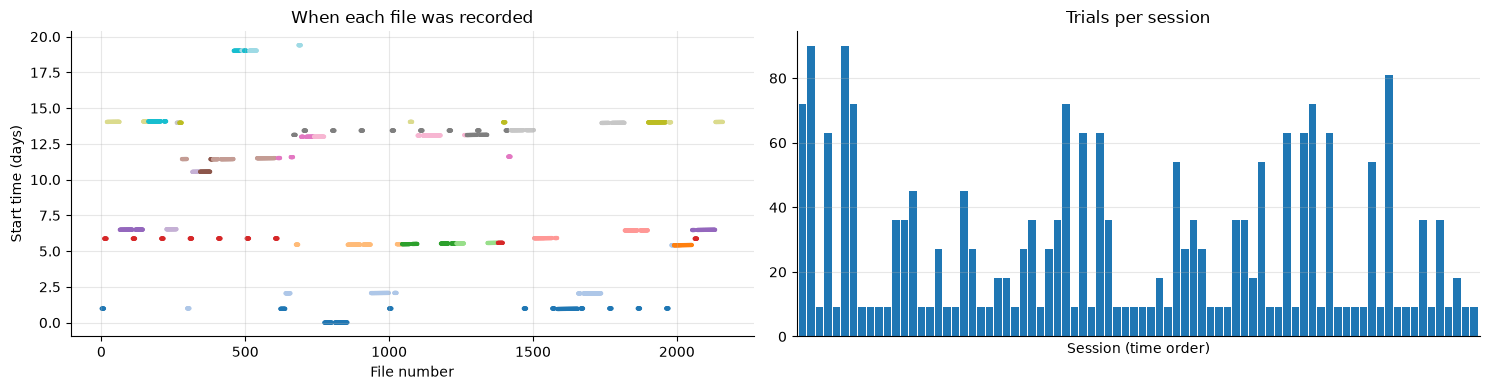

In [18]:
order = trials.sort_values("t_start")
gap = order["t_start"].values[1:] - order["t_end"].values[:-1]
order["session"] = np.cumsum(np.r_[True, gap > cfg["session_gap_seconds"]])
trials["session"] = order["session"]                     # aligned by index
trials_k["session"] = trials_k["filename"].map(dict(zip(trials["filename"], trials["session"])))

sizes = trials.groupby("session").size()
days = (trials["t_start"].max() - trials["t_start"].min()) / 86400
rho = stats.spearmanr(trials.index, trials["t_start"]).statistic
print(f"Sessions: {trials['session'].nunique()} over {days:.1f} days")
print("Trials per session:", sizes.value_counts().sort_index().to_dict())
print("Every session is a multiple of 9 trials:", bool((sizes % 9 == 0).all()))
print(f"Gap between trials inside a session: median {np.median(gap[gap <= 60]):.2f} s")
print(f"File order vs recording order (Spearman rho): {rho:.2f}")
per_s = pd.crosstab(trials["session"], trials["label"])
print("Sessions with both classes:", int(((per_s > 0).sum(1) == 2).sum()), "of", len(per_s))

fig, ax = plt.subplots(1, 2, figsize=(15, 4))
ax[0].scatter(np.arange(len(trials)) + 1, (trials["t_start"] - trials["t_start"].min()) / 86400,
              c=trials["session"], cmap="tab20", s=4)
ax[0].set_xlabel("File number"); ax[0].set_ylabel("Start time (days)"); ax[0].set_title("When each file was recorded")
sizes.plot(kind="bar", ax=ax[1], width=0.9); ax[1].set_xticks([]); ax[1].set_xlabel("Session (time order)")
ax[1].set_title("Trials per session")
plt.tight_layout(); plt.show()

### 3.4.2 Duplicated trial files
- **Did:** Grouped files with an identical signal fingerprint (hash), then compared their labels.
- **Logic:** If the labels were correct, every copy would carry the **same** label (100 % agreement). If labels were random, about 50 % would agree.

In [19]:
dup = trials[trials.duplicated("hash", keep=False)]
groups = dup.groupby("hash")
dup_table = groups.agg(files=("filename", lambda s: " = ".join(s)), labels=("label", lambda s: " / ".join(s)),
                       n=("filename", "size"), same_label=("label", lambda s: s.nunique() == 1)).reset_index(drop=True)
dup_table.to_csv(f"{OUT}/duplicates.csv", index=False)
n_pairs, n_agree = len(dup_table), int(dup_table["same_label"].sum())
print(f"Duplicate groups: {n_pairs} (sizes: {dup_table['n'].value_counts().to_dict()}) -> {len(dup)} files involved")
print(f"Groups with the same label: {n_agree} of {n_pairs} ({n_agree / n_pairs:.0%})")
print(f"Binomial test vs random labels (50%): p = {stats.binomtest(n_agree, n_pairs, 0.5).pvalue:.3f}")
print("If labels were correct we would expect 100% agreement.")
nums = dup["filename"].map(lambda s: num(s))
print(f"File numbers involved: {nums.min()}–{nums.max()}")
dup_table.head(10)

Duplicate groups: 36 (sizes: {2: 36}) -> 72 files involved
Groups with the same label: 12 of 36 (33%)
Binomial test vs random labels (50%): p = 0.065
If labels were correct we would expect 100% agreement.
File numbers involved: 37–1962


,files,labels,n,same_label
0,cellula_MI_data_671.csv = cellula_MI_data_1319.csv,LEFT / RIGHT,2,False
1,cellula_MI_data_42.csv = cellula_MI_data_1077.csv,LEFT / RIGHT,2,False
2,cellula_MI_data_673.csv = cellula_MI_data_1321.csv,LEFT / LEFT,2,True
3,cellula_MI_data_1402.csv = cellula_MI_data_1960.csv,RIGHT / LEFT,2,False
4,cellula_MI_data_1396.csv = cellula_MI_data_1954.csv,LEFT / RIGHT,2,False
5,cellula_MI_data_40.csv = cellula_MI_data_1075.csv,LEFT / RIGHT,2,False
6,cellula_MI_data_675.csv = cellula_MI_data_1323.csv,LEFT / LEFT,2,True
7,cellula_MI_data_668.csv = cellula_MI_data_1316.csv,RIGHT / LEFT,2,False
8,cellula_MI_data_669.csv = cellula_MI_data_1317.csv,LEFT / RIGHT,2,False
9,cellula_MI_data_679.csv = cellula_MI_data_922.csv,LEFT / RIGHT,2,False


### 3.4.3 Is the label order shifted?
- **Did:** `labels.csv` has 2400 rows for 2160 files and no filenames. We tried every shift from −240 to +240 (file *N* gets label *N + shift*) and measured how many duplicate groups would then agree.
- **Logic:** If the labels were only shifted, one shift would give ~100 % agreement.

Agreement with our pairing (shift 0): 33%
Best shift: 120 -> 72% | shifts reaching 100%: 0


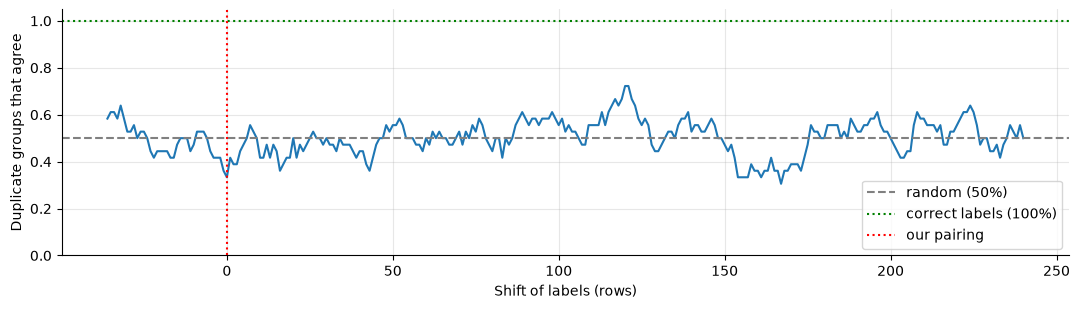

In [20]:
all_labels = labels_raw["label"].astype(str).str.strip().str.upper().values
grp_nums = [dup.loc[dup["hash"] == h, "filename"].map(num).values for h in dup["hash"].unique()]
res = []
for shift in range(-240, 241):
    idx = [g - 1 + shift for g in grp_nums]
    if any((i < 0).any() or (i >= len(all_labels)).any() for i in idx):
        continue
    res.append({"shift": shift, "agree": np.mean([len(set(all_labels[i])) == 1 for i in idx])})
res = pd.DataFrame(res)
best = res.loc[res["agree"].idxmax()]
print(f"Agreement with our pairing (shift 0): {res.loc[res['shift'] == 0, 'agree'].item():.0%}")
print(f"Best shift: {int(best['shift'])} -> {best['agree']:.0%} | shifts reaching 100%: {(res['agree'] == 1).sum()}")

plt.figure(figsize=(13, 3.2))
plt.plot(res["shift"], res["agree"]); plt.axhline(0.5, color="grey", ls="--", label="random (50%)")
plt.axhline(1.0, color="green", ls=":", label="correct labels (100%)"); plt.axvline(0, color="red", ls=":", label="our pairing")
plt.xlabel("Shift of labels (rows)"); plt.ylabel("Duplicate groups that agree"); plt.legend(); plt.ylim(0, 1.05)
plt.show()

### 3.4.4 Do sessions differ more than LEFT vs RIGHT?
- **Did:** For log mu power on C3 and C4, measured how much of the variation between trials is explained by the **session** vs by the **label** (eta², share of variance). Because 80 groups always explain a little by chance, we also show eta² for randomly shuffled sessions as the "chance" level.

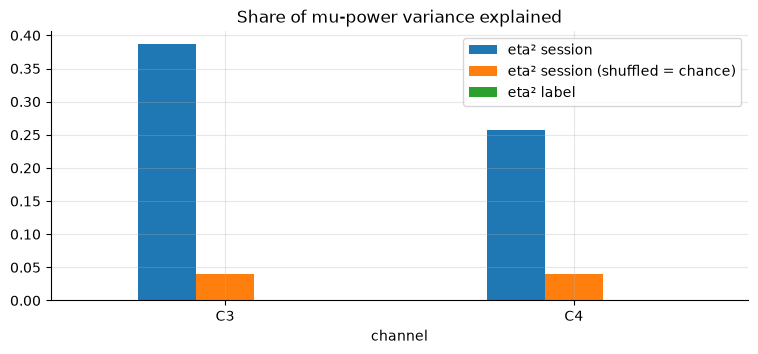

,eta² session,eta² session (shuffled = chance),eta² label
channel,,,
C3,0.3872,0.0398,0.0007
C4,0.2577,0.0394,0.0009


In [21]:
def eta2(values, groups_):
    g = pd.Series(values).groupby(groups_)
    return float(((g.mean() - values.mean()) ** 2 * g.size()).sum() / ((values - values.mean()) ** 2).sum())

lp_mu = np.log(band_power(P_nocar, 8, 12))
sess = trials_k["session"].values
rows_ = []
for ch in (C3, C4):
    v = lp_mu[:, ch]
    rows_.append({"channel": CH[ch], "eta² session": eta2(v, sess),
                  "eta² session (shuffled = chance)": np.mean([eta2(v, np.random.default_rng(s).permutation(sess)) for s in range(20)]),
                  "eta² label": eta2(v, y)})
eta_tab = pd.DataFrame(rows_).set_index("channel")
eta_tab.plot(kind="bar", figsize=(9, 3.5), rot=0, title="Share of mu-power variance explained"); plt.show()
eta_tab.round(4)

<!--N:e344-->
**Noticed:** _to fill_

### 3.4.5 Is the ERD clearer late in the trial (4–9 s)?
- **Did:** Repeated the 3.2.3 lateralization test using only 4–9 s of each epoch.

In [22]:
s45 = int((4 - cfg["epoch_seconds"][0]) * FS)
f_l, P_late = welch(X_ep_nocar[:, :, s45:], fs=FS, nperseg=2 * FS, axis=-1)
late_rows = []
for win, (ff, P) in {"1–9 s": (f, P_nocar), "4–9 s": (f_l, P_late)}.items():
    for bname, (lo_, hi_) in BANDS.items():
        bpw = P[..., (ff >= lo_) & (ff <= hi_)].mean(-1)
        li = (bpw[:, C4] - bpw[:, C3]) / (bpw[:, C4] + bpw[:, C3])
        late_rows.append({"window": win, "band": bname, "Cohen d (RIGHT−LEFT)": cohen_d(li[y == "LEFT"], li[y == "RIGHT"]),
                          "Mann-Whitney p": stats.mannwhitneyu(li[y == "LEFT"], li[y == "RIGHT"]).pvalue})
pd.DataFrame(late_rows).round(3)

,window,band,Cohen d (RIGHT−LEFT),Mann-Whitney p
0,1–9 s,mu 8–12,0.026,0.356
1,1–9 s,beta 13–30,-0.006,0.825
2,4–9 s,mu 8–12,-0.018,0.775
3,4–9 s,beta 13–30,-0.026,0.876


# Stage 4 — Features / DL preparation
**Task says (Table 3):** *"CSP features or prepare tensors for EEGNet"* → deliverable *"Feature matrix or DataLoaders"*. We do both.

## 4.0 Final dataset and the shared cross-validation folds
**Task says:** *"Always use subject-aware or trial-aware cross-validation"* and *"Use the same train/validation/test split (or same CV folds) for every model so results are comparable."*
- **Did:**
  1. Removed duplicated files found in 3.4.2: if the copies **disagree** on the label, both are dropped (we can't know which is right); if they agree, one copy is kept.
  2. Made **5 folds split by session** (`StratifiedGroupKFold`): no session is ever in both train and test, and each fold keeps LEFT/RIGHT balanced.
  3. Saved the folds so every model uses exactly the same splits.

In [23]:
from sklearn.model_selection import StratifiedGroupKFold, GroupShuffleSplit

drop = set()
for _, g in dup.groupby("hash"):
    files_ = list(g["filename"])
    drop |= set(files_) if g["label"].nunique() > 1 else set(files_[1:])
mask = ~trials_k["filename"].isin(drop).values
print(f"Duplicated files dropped: {(~mask).sum()} (of the {len(drop)} flagged, the rest were already rejected in Step 4)")

X_nocar, X_car = X_ep_nocar[mask], X_ep_car[mask]
yb = (y[mask] == "RIGHT").astype(int)                    # LEFT = 0, RIGHT = 1
groups = trials_k.loc[mask, "session"].values
final_files = trials_k.loc[mask, "filename"].values
print("Final data:", X_nocar.shape, "| LEFT", (yb == 0).sum(), "| RIGHT", (yb == 1).sum(), "| sessions", len(np.unique(groups)))

cv = StratifiedGroupKFold(n_splits=cfg["cv_folds"], shuffle=True, random_state=SEED)
folds = list(cv.split(X_nocar, yb, groups))
fold_tab = pd.DataFrame([{"fold": k + 1, "train trials": len(tr), "test trials": len(te),
                          "test sessions": len(np.unique(groups[te])), "test RIGHT share": yb[te].mean(),
                          "sessions shared train/test": len(set(groups[tr]) & set(groups[te]))}
                         for k, (tr, te) in enumerate(folds)])
with open(f"{OUT}/cv_folds.json", "w") as fh:
    json.dump({f"fold_{k + 1}": final_files[te].tolist() for k, (_, te) in enumerate(folds)}, fh)
print(f"Saved {OUT}/cv_folds.json")
fold_tab.round(3)

Duplicated files dropped: 60 (of the 60 flagged, the rest were already rejected in Step 4)
Final data: (1831, 4, 2000) | LEFT 916 | RIGHT 915 | sessions 78
Saved outputs/cv_folds.json


,fold,train trials,test trials,test sessions,test RIGHT share,sessions shared train/test
0,1,1487,344,10,0.483,0
1,2,1479,352,12,0.511,0
2,3,1459,372,20,0.513,0
3,4,1463,368,17,0.484,0
4,5,1436,395,19,0.506,0


## 4.1 CSP features (feature matrix)
**Task says (Table 2):** CSP + SVM input = *"Log-variance features after CSP"*.
- **Did:** Band-passed the epochs to **8–30 Hz** (the task's "tighter" band = mu + beta). Learned CSP (4 components) on the **training** part of fold 1 only, turned every trial into 4 log-variance features, and measured how well each feature separates LEFT/RIGHT on the **unseen** test part.
- **Why:** CSP finds channel mixes whose power differs most between the classes. It is the classic feature for motor imagery.

Feature matrix: (1831, 4) -> saved outputs/csp_features_fold1.npy
CSP 1: effect size on fold-1 TEST trials d = +0.141 | on TRAIN trials d = +0.023
CSP 2: effect size on fold-1 TEST trials d = +0.234 | on TRAIN trials d = -0.055
CSP 3: effect size on fold-1 TEST trials d = +0.194 | on TRAIN trials d = -0.019
CSP 4: effect size on fold-1 TEST trials d = +0.229 | on TRAIN trials d = +0.001


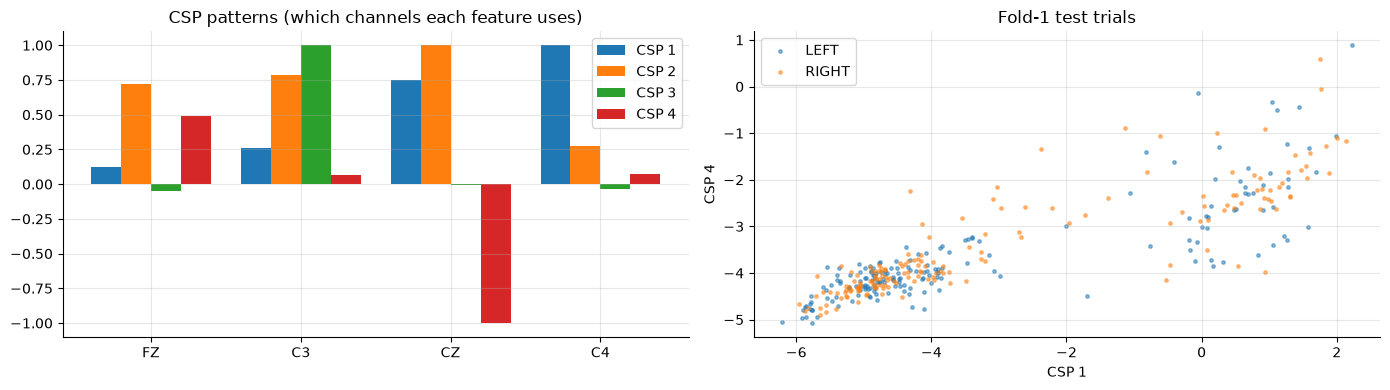

In [24]:
import mne
from mne.decoding import CSP
mne.set_log_level("ERROR")

X_csp = bp.csp_input(X_nocar, cfg)
X_csp_car = bp.csp_input(X_car, cfg)

tr, te = folds[0]
csp = CSP(n_components=cfg["csp_components"], reg="ledoit_wolf", log=True).fit(X_csp[tr], yb[tr])
F = csp.transform(X_csp)
np.save(f"{OUT}/csp_features_fold1.npy", F)
print("Feature matrix:", F.shape, f"-> saved {OUT}/csp_features_fold1.npy")
for k in range(F.shape[1]):
    print(f"CSP {k + 1}: effect size on fold-1 TEST trials d = {cohen_d(F[te][yb[te] == 0, k], F[te][yb[te] == 1, k]):+.3f}"
          f" | on TRAIN trials d = {cohen_d(F[tr][yb[tr] == 0, k], F[tr][yb[tr] == 1, k]):+.3f}")

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
pat = csp.patterns_[:cfg["csp_components"]]
for k in range(len(pat)):
    ax[0].bar(np.arange(4) + 0.2 * (k - 1.5), pat[k] / abs(pat[k]).max(), 0.2, label=f"CSP {k + 1}")
ax[0].set_xticks(range(4), CH); ax[0].set_title("CSP patterns (which channels each feature uses)"); ax[0].legend()
for lab, v in (("LEFT", 0), ("RIGHT", 1)):
    s_ = te[yb[te] == v]
    ax[1].scatter(F[s_, 0], F[s_, -1], s=6, alpha=0.5, color=COL[lab], label=lab)
ax[1].set_xlabel("CSP 1"); ax[1].set_ylabel(f"CSP {F.shape[1]}"); ax[1].set_title("Fold-1 test trials"); ax[1].legend()
plt.tight_layout(); plt.show()

## 4.2 Tensors and DataLoaders for the deep models
**Task says (Table 2):** EEGNet input = *"Epoched multi-channel EEG (raw or lightly filtered)"*.
- **Did:** `bp.dl_input`: the 0.5–40 Hz epochs (lightly filtered, no CAR), downsampled 250 → 125 Hz (EEGNet was designed around ~128 Hz; 40 Hz is far below the new 62.5 Hz limit, so nothing useful is lost and training is 2× faster), z-scored (Step 8), shaped `(trials, 1, channels, samples)` for PyTorch.

In [25]:
import torch
from torch.utils.data import DataLoader, TensorDataset
torch.manual_seed(SEED)

X_dl = bp.dl_input(X_nocar, cfg)
print("Deep-learning input:", X_dl.shape, "| rate", FS // cfg["dl_downsample"], "Hz | dtype", X_dl.dtype)
tr, te = folds[0]
train_loader = DataLoader(TensorDataset(torch.from_numpy(X_dl[tr]), torch.from_numpy(yb[tr]).long()),
                          batch_size=cfg["dl"]["batch_size"], shuffle=True)
xb, yb_ = next(iter(train_loader))
print("One batch:", tuple(xb.shape), "| labels in batch:", yb_.tolist()[:12], "...")
print("Fold 1 batches per epoch:", len(train_loader))

Deep-learning input: (1831, 1, 4, 1000) | rate 125 Hz | dtype float32
One batch: (32, 1, 4, 1000) | labels in batch: [0, 0, 1, 0, 1, 0, 0, 0, 1, 0, 0, 0] ...
Fold 1 batches per epoch: 47


# Stage 5 — Modeling
**Task says:** *"Start simple and strong, then add more complex models for comparison."* Order (Table 2): **1** CSP + SVM → **2** EEGNet → **3** CNN / CNN-LSTM (*"use if EEGNet is not enough"*) → **4** Transformer (*"only if time and data allow"*).
**Input / Output (task):** clean multi-channel EEG or CSP features → **LEFT or RIGHT, with probability scores**.

Every model is scored on the **same 5 session-based folds** with the same metrics. In the deep models, early stopping uses a validation set made of **training sessions only** (15 %), so the test fold is never used for any decision.

In [26]:
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay, roc_curve)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

def scores(y_true, prob):
    pred = (prob >= 0.5).astype(int)
    return {"Accuracy": accuracy_score(y_true, pred), "Balanced Acc": balanced_accuracy_score(y_true, pred),
            "F1": f1_score(y_true, pred, zero_division=0), "AUC": roc_auc_score(y_true, prob)}

def summary(per_fold):
    cols = ["Accuracy", "Balanced Acc", "F1", "AUC"]
    return pd.DataFrame({"mean": per_fold[cols].mean(), "std": per_fold[cols].std()}).T.round(3)

RESULTS = {}      # model name -> {"per_fold", "oof"}

## 5.1 Priority 1 (baseline): CSP + SVM
**Task says:** *"Strong classic method for Motor Imagery. Implement first. Easy to interpret."*
- **Did:** Pipeline = CSP (4 components, log-variance) → standardize → linear SVM with probability output. Trained and tested on each fold. Also ran the **CAR** version to settle the Step 5 question.

In [27]:
def make_csp_svm():
    return make_pipeline(CSP(n_components=cfg["csp_components"], reg="ledoit_wolf", log=True),
                         StandardScaler(), SVC(kernel="linear", probability=True, random_state=SEED))

def run_cv_sklearn(make, X, y_):
    oof, rows_ = np.zeros(len(y_)), []
    for k, (tr, te) in enumerate(folds):
        mdl = make().fit(X[tr], y_[tr])
        p = mdl.predict_proba(X[te])[:, 1]; oof[te] = p
        rows_.append({"fold": k + 1, "Train acc": accuracy_score(y_[tr], (mdl.predict_proba(X[tr])[:, 1] >= 0.5).astype(int)),
                      **scores(y_[te], p)})
    return pd.DataFrame(rows_), oof

t0 = time.time()
pf, oof = run_cv_sklearn(make_csp_svm, X_csp, yb)
RESULTS["CSP + SVM"] = {"per_fold": pf, "oof": oof}
pf_car, oof_car = run_cv_sklearn(make_csp_svm, X_csp_car, yb)
print(f"done in {time.time() - t0:.0f} s\n")
print("CSP + SVM, no CAR (main):"); display(pf.round(3)); display(summary(pf))
print("CSP + SVM, with CAR (Step 5 comparison):"); display(summary(pf_car))

done in 29 s

CSP + SVM, no CAR (main):


,fold,Train acc,Accuracy,Balanced Acc,F1,AUC
0,1,0.485,0.552,0.539,0.238,0.544
1,2,0.527,0.486,0.489,0.403,0.489
2,3,0.482,0.527,0.521,0.616,0.527
3,4,0.488,0.481,0.496,0.638,0.483
4,5,0.486,0.499,0.494,0.631,0.480


,Accuracy,Balanced Acc,F1,AUC
mean,0.509,0.508,0.505,0.504
std,0.030,0.021,0.179,0.029


CSP + SVM, with CAR (Step 5 comparison):


,Accuracy,Balanced Acc,F1,AUC
mean,0.510,0.508,0.549,0.497
std,0.032,0.026,0.127,0.049


## 5.2 Priority 2: EEGNet
**Task says:** *"Designed specifically for EEG. Good deep-learning starting point, few parameters."*
- **Did:** EEGNet (Lawhern et al., 2018). Its three blocks mirror the classic pipeline, but are learned: **temporal** filter (like the band-pass), **spatial** filter (like CSP), **separable** filter (short patterns over time). Adam, lr 0.001, batch 32, up to 40 epochs, early stopping (patience 8) on the training-session validation set.

EEGNet parameters: 2162
  fold 1: 16 epochs, test AUC 0.490
  fold 2: 16 epochs, test AUC 0.501
  fold 3: 14 epochs, test AUC 0.526
  fold 4: 9 epochs, test AUC 0.516
  fold 5: 10 epochs, test AUC 0.479
done in 2.2 min


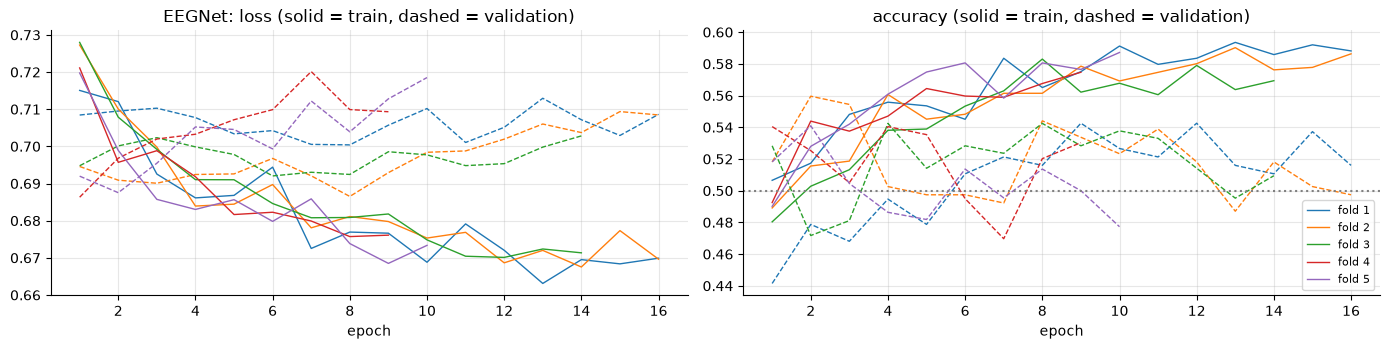

,fold,epochs run,best epoch,Train acc,Val acc,Accuracy,Balanced Acc,F1,AUC
0,1,16,8,0.637,0.516,0.488,0.491,0.511,0.490
1,2,16,8,0.622,0.544,0.500,0.500,0.497,0.501
2,3,14,6,0.589,0.528,0.508,0.509,0.490,0.526
3,4,9,1,0.551,0.540,0.500,0.502,0.523,0.516
4,5,10,2,0.571,0.541,0.478,0.479,0.461,0.479


,Accuracy,Balanced Acc,F1,AUC
mean,0.495,0.496,0.497,0.502
std,0.012,0.012,0.024,0.019


In [28]:
def run_cv_torch(name, X, y_, verbose=True):
    oof, rows_, hists = np.zeros(len(y_)), [], []
    for k, (tr, te) in enumerate(folds):
        gss = GroupShuffleSplit(n_splits=1, test_size=cfg["dl"]["val_share"], random_state=SEED + k)
        a_, b_ = next(gss.split(tr, groups=groups[tr])); itr, iva = tr[a_], tr[b_]
        net, h = bp.train_torch(name, X[itr], y_[itr], X[iva], y_[iva], cfg, seed=SEED + k)
        p = bp.predict_torch(net, X[te]); oof[te] = p
        best = int(h["val_loss"].idxmin())
        rows_.append({"fold": k + 1, "epochs run": len(h), "best epoch": best + 1,
                      "Train acc": accuracy_score(y_[itr], (bp.predict_torch(net, X[itr]) >= 0.5).astype(int)),
                      "Val acc": h.loc[best, "val_acc"], **scores(y_[te], p)})
        hists.append(h)
        if verbose: print(f"  fold {k + 1}: {len(h)} epochs, test AUC {rows_[-1]['AUC']:.3f}")
    return pd.DataFrame(rows_), oof, hists

def plot_curves(hists, title):
    fig, ax = plt.subplots(1, 2, figsize=(14, 3.6))
    for k, h in enumerate(hists):
        ax[0].plot(h["epoch"], h["train_loss"], color=f"C{k}", lw=1); ax[0].plot(h["epoch"], h["val_loss"], color=f"C{k}", ls="--", lw=1)
        ax[1].plot(h["epoch"], h["train_acc"], color=f"C{k}", lw=1, label=f"fold {k + 1}"); ax[1].plot(h["epoch"], h["val_acc"], color=f"C{k}", ls="--", lw=1)
    ax[0].set_title(f"{title}: loss (solid = train, dashed = validation)"); ax[1].set_title("accuracy (solid = train, dashed = validation)")
    ax[1].axhline(0.5, color="grey", ls=":"); ax[1].legend(fontsize=8)
    for a_ in ax: a_.set_xlabel("epoch")
    plt.tight_layout(); plt.show()

print("EEGNet parameters:", sum(p.numel() for p in bp.EEGNet(4, X_dl.shape[-1]).parameters()))
t0 = time.time()
pf_eeg, oof_eeg, h_eeg = run_cv_torch("EEGNet", X_dl, yb)
print(f"done in {(time.time() - t0) / 60:.1f} min")
RESULTS["EEGNet"] = {"per_fold": pf_eeg, "oof": oof_eeg, "hists": h_eeg}
plot_curves(h_eeg, "EEGNet")
display(pf_eeg.round(3)); display(summary(pf_eeg))

## 5.3 Priority 3: CNN-LSTM
**Task says:** *"Can capture more complex patterns. Use if EEGNet is not enough."* Input: *"Same as EEGNet"*.
- **Did:** Two 1-D convolution blocks (learn short local patterns and shorten the sequence 16×) → LSTM (reads how those patterns change over the 8 s) → classifier. Same input, folds, early stopping and metrics as EEGNet.
- **Why run it:** EEGNet did not reach a useful score, which is exactly the task's condition for trying Priority 3.

CNN-LSTM parameters: 12690
  fold 1: 9 epochs, test AUC 0.467
  fold 2: 11 epochs, test AUC 0.549
  fold 3: 16 epochs, test AUC 0.462
  fold 4: 10 epochs, test AUC 0.501
  fold 5: 16 epochs, test AUC 0.476
done in 1.2 min


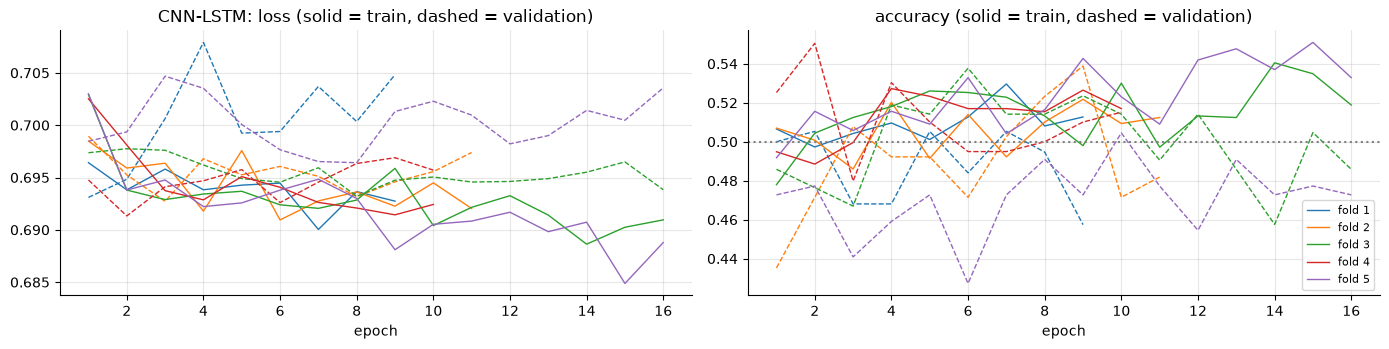

,fold,epochs run,best epoch,Train acc,Val acc,Accuracy,Balanced Acc,F1,AUC
0,1,9,1,0.518,0.500,0.456,0.454,0.414,0.467
1,2,11,3,0.507,0.508,0.526,0.523,0.577,0.549
2,3,16,8,0.535,0.514,0.454,0.452,0.504,0.462
3,4,10,2,0.515,0.551,0.500,0.496,0.421,0.501
4,5,16,8,0.547,0.491,0.468,0.470,0.371,0.476


,Accuracy,Balanced Acc,F1,AUC
mean,0.481,0.479,0.457,0.491
std,0.031,0.030,0.082,0.036


In [29]:
print("CNN-LSTM parameters:", sum(p.numel() for p in bp.CNNLSTM(4, X_dl.shape[-1]).parameters()))
t0 = time.time()
pf_cl, oof_cl, h_cl = run_cv_torch("CNN-LSTM", X_dl, yb)
print(f"done in {(time.time() - t0) / 60:.1f} min")
RESULTS["CNN-LSTM"] = {"per_fold": pf_cl, "oof": oof_cl, "hists": h_cl}
plot_curves(h_cl, "CNN-LSTM")
display(pf_cl.round(3)); display(summary(pf_cl))

# Stage 6 — Evaluation
**Task says:** *"Report Accuracy, Balanced Accuracy, F1-score, Confusion Matrix, and (if possible) AUC. Always use subject-aware or trial-aware cross-validation."* → deliverable *"Final performance numbers"*.

## 6.1 Final performance numbers (5 session-based folds)

Saved outputs/final_results.csv  (mean ± std over 5 folds)


,Accuracy,Balanced Acc,F1,AUC,Train acc
Model,,,,,
CSP + SVM,0.509 ± 0.030,0.508 ± 0.021,0.505 ± 0.179,0.504 ± 0.029,0.494
EEGNet,0.495 ± 0.012,0.496 ± 0.012,0.497 ± 0.024,0.502 ± 0.019,0.594
CNN-LSTM,0.481 ± 0.031,0.479 ± 0.030,0.457 ± 0.082,0.491 ± 0.036,0.524


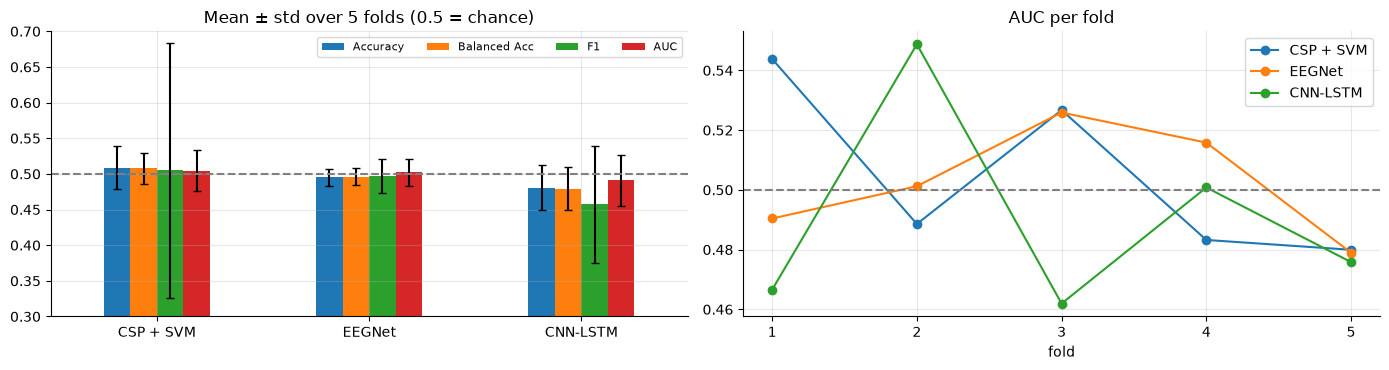

In [30]:
cols = ["Accuracy", "Balanced Acc", "F1", "AUC"]
final = pd.DataFrame({name: {c: f"{r['per_fold'][c].mean():.3f} ± {r['per_fold'][c].std():.3f}" for c in cols}
                      for name, r in RESULTS.items()}).T
final["Train acc"] = [f"{r['per_fold']['Train acc'].mean():.3f}" for r in RESULTS.values()]
final.index.name = "Model"
final.to_csv(f"{OUT}/final_results.csv")
print(f"Saved {OUT}/final_results.csv  (mean ± std over 5 folds)")
display(final)

fig, ax = plt.subplots(1, 2, figsize=(14, 3.8))
mean_tab = pd.DataFrame({n: r["per_fold"][cols].mean() for n, r in RESULTS.items()}).T
err_tab = pd.DataFrame({n: r["per_fold"][cols].std() for n, r in RESULTS.items()}).T
mean_tab.plot(kind="bar", yerr=err_tab, ax=ax[0], rot=0, capsize=3); ax[0].axhline(0.5, color="grey", ls="--")
ax[0].set_ylim(0.3, 0.7); ax[0].set_title("Mean ± std over 5 folds (0.5 = chance)"); ax[0].legend(fontsize=8, ncol=4)
for n, r in RESULTS.items():
    ax[1].plot(range(1, 6), r["per_fold"]["AUC"], "o-", label=n)
ax[1].axhline(0.5, color="grey", ls="--"); ax[1].set_xticks(range(1, 6)); ax[1].set_xlabel("fold"); ax[1].set_title("AUC per fold"); ax[1].legend()
plt.tight_layout(); plt.show()

## 6.2 Confusion matrices and ROC curves
- **Did:** Each trial is predicted once, by the model of the fold where it was in the test set (out-of-fold predictions), so the matrices cover all trials without any trial being seen in training.

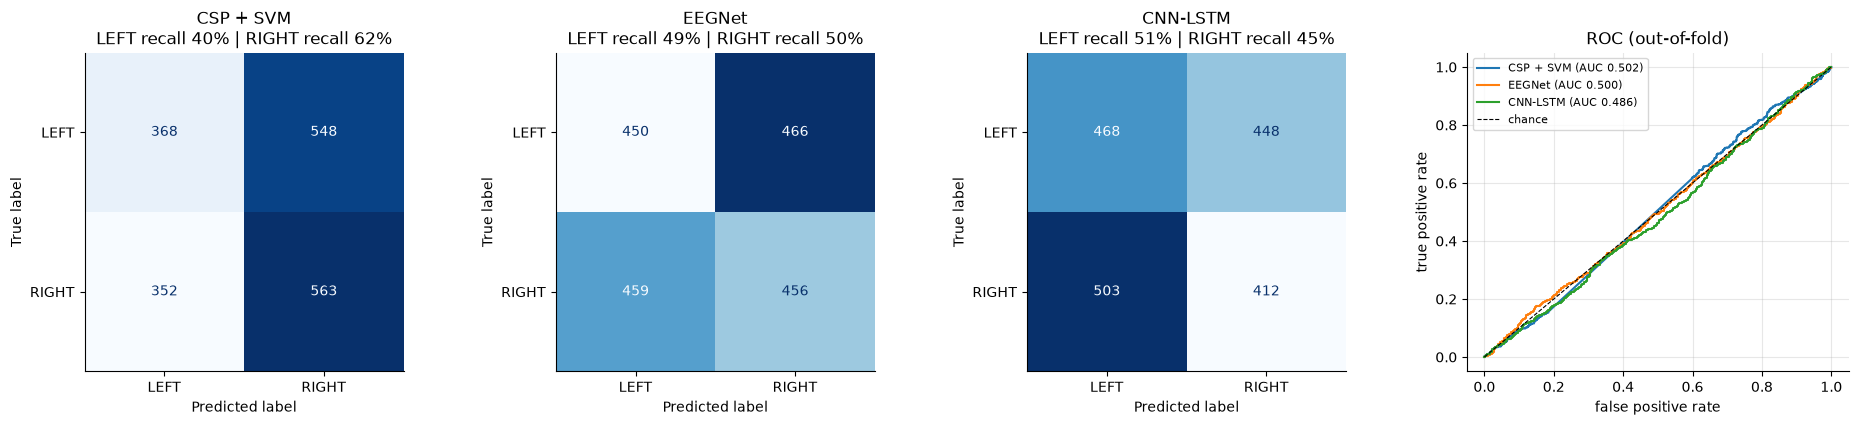

In [31]:
fig, ax = plt.subplots(1, len(RESULTS) + 1, figsize=(19, 4.3))
for k, (n, r) in enumerate(RESULTS.items()):
    pred = (r["oof"] >= 0.5).astype(int)
    cm = confusion_matrix(yb, pred)
    ConfusionMatrixDisplay(cm, display_labels=["LEFT", "RIGHT"]).plot(ax=ax[k], cmap="Blues", colorbar=False)
    ax[k].set_title(f"{n}\nLEFT recall {cm[0, 0] / cm[0].sum():.0%} | RIGHT recall {cm[1, 1] / cm[1].sum():.0%}"); ax[k].grid(False)
    fpr, tpr, _ = roc_curve(yb, r["oof"]); ax[-1].plot(fpr, tpr, label=f"{n} (AUC {roc_auc_score(yb, r['oof']):.3f})")
ax[-1].plot([0, 1], [0, 1], "k--", lw=0.8, label="chance"); ax[-1].set_title("ROC (out-of-fold)"); ax[-1].legend(fontsize=8)
ax[-1].set_xlabel("false positive rate"); ax[-1].set_ylabel("true positive rate")
plt.tight_layout(); plt.savefig(f"{OUT}/confusion_matrices_roc.png", dpi=130); plt.show()

## 6.3 Is any model better than chance?
- **Did:** Two independent tests:
  1. **Binomial test:** is the number of correct out-of-fold predictions higher than a coin flip would give?
  2. **Label-shuffling (permutation) test:** retrain the same model on the same folds with **randomly shuffled labels**. If the real labels don't score clearly higher than shuffled ones, the model learned nothing about LEFT/RIGHT. CSP + SVM: 30 shuffles. Deep models: 1 shuffle each (each run takes minutes on CPU).

CSP + SVM permutations: 304 s
EEGNet shuffled run: 1.5 min | train acc with shuffled labels 0.554 vs real 0.594
CNN-LSTM shuffled run: 1.1 min | train acc with shuffled labels 0.523 vs real 0.524


,correct,pooled AUC,binomial p (> 50%),shuffled AUC,permutation p
Model,,,,,
CSP + SVM,931 / 1831,0.502,0.242,"0.494 (0.470–0.525), n=30",0.29
EEGNet,906 / 1831,0.500,0.680,"0.485, n=1",NaN
CNN-LSTM,880 / 1831,0.486,0.954,"0.465, n=1",NaN


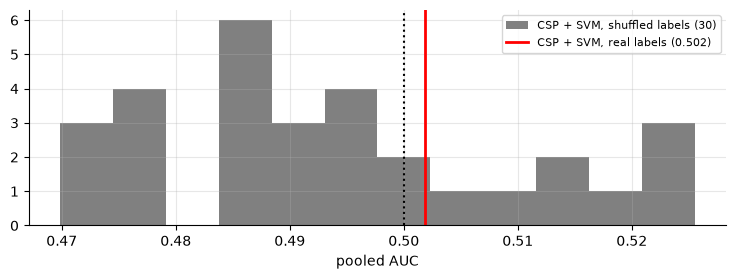

In [32]:
rows_ = []
for n, r in RESULTS.items():
    correct = int(((r["oof"] >= 0.5).astype(int) == yb).sum())
    rows_.append({"Model": n, "correct": f"{correct} / {len(yb)}", "pooled AUC": roc_auc_score(yb, r["oof"]),
                  "binomial p (> 50%)": stats.binomtest(correct, len(yb), 0.5, alternative="greater").pvalue})
chance = pd.DataFrame(rows_).set_index("Model")

t0 = time.time()
perm_auc = []
for s in range(30):
    y_sh = np.random.default_rng(s).permutation(yb)
    _, o = run_cv_sklearn(make_csp_svm, X_csp, y_sh); perm_auc.append(roc_auc_score(y_sh, o))
perm_auc = np.array(perm_auc)
real = roc_auc_score(yb, RESULTS["CSP + SVM"]["oof"])
chance.loc["CSP + SVM", "shuffled AUC"] = f"{perm_auc.mean():.3f} ({perm_auc.min():.3f}–{perm_auc.max():.3f}), n=30"
chance.loc["CSP + SVM", "permutation p"] = (np.sum(perm_auc >= real) + 1) / (len(perm_auc) + 1)
print(f"CSP + SVM permutations: {time.time() - t0:.0f} s")

shuffle_train = {}
for n in ("EEGNet", "CNN-LSTM"):
    t0 = time.time()
    y_sh = np.random.default_rng(0).permutation(yb)
    pf_sh, o, _ = run_cv_torch(n, X_dl, y_sh, verbose=False)
    chance.loc[n, "shuffled AUC"] = f"{roc_auc_score(y_sh, o):.3f}, n=1"
    shuffle_train[n] = (pf_sh["Train acc"].mean(), RESULTS[n]["per_fold"]["Train acc"].mean())
    print(f"{n} shuffled run: {(time.time() - t0) / 60:.1f} min | train acc with shuffled labels {shuffle_train[n][0]:.3f} vs real {shuffle_train[n][1]:.3f}")

display(chance.round(3))
plt.figure(figsize=(9, 2.8))
plt.hist(perm_auc, bins=12, color="grey", label="CSP + SVM, shuffled labels (30)")
plt.axvline(real, color="red", lw=2, label=f"CSP + SVM, real labels ({real:.3f})")
plt.axvline(0.5, color="black", ls=":"); plt.xlabel("pooled AUC"); plt.legend(fontsize=8); plt.show()

## 6.4 Model comparison and choice of the model for the demo

In [33]:
comp = pd.DataFrame({n: {"mean AUC": r["per_fold"]["AUC"].mean(), "mean Balanced Acc": r["per_fold"]["Balanced Acc"].mean(),
                         "train − test acc gap": r["per_fold"]["Train acc"].mean() - r["per_fold"]["Accuracy"].mean(),
                         "folds with AUC > 0.5": int((r["per_fold"]["AUC"] > 0.5).sum())}
                     for n, r in RESULTS.items()}).T
best_model = comp["mean AUC"].astype(float).idxmax()
display(comp.round(3))
print("Best mean AUC:", best_model)

,mean AUC,mean Balanced Acc,train − test acc gap,folds with AUC > 0.5
CSP + SVM,0.504,0.508,-0.015,2.0
EEGNet,0.502,0.496,0.099,3.0
CNN-LSTM,0.491,0.479,0.044,2.0


Best mean AUC: CSP + SVM


# Stage 7 — Deployment
**Task says (§6.2):**
- *"Save the final model with joblib (sklearn) or torch.save / onnx (deep models)."*
- *"Keep preprocessing code identical between training and inference (same filters, same window)."*
- *"Version the final model and the exact preprocessing code that produced the features it expects."*
- *"Start with Streamlit — load the model, accept an uploaded Excel/CSV trial, run inference, show LEFT/RIGHT + confidence."*
- *"Add a simple 'example trial' button."*

## 7.1 Train the final models on all the data and save them
- **Did:** Cross-validation measures a model but keeps none. We trained each model once on **all** final trials. Deep models train for the **median best epoch** found in cross-validation (no test data left for early stopping). Saved: `csp_svm.joblib` (joblib), `eegnet.pt` and `cnn_lstm.pt` (torch.save), and `model_card.json`. The model card holds the version, the exact config, the artifact limits, the CV scores and the data warning.

In [34]:
import joblib, datetime

final_models = {"CSP + SVM": make_csp_svm().fit(X_csp, yb)}
joblib.dump(final_models["CSP + SVM"], f"{MODELS_DIR}/{bp.MODEL_FILES['CSP + SVM']}")
final_epochs = {}
for n in ("EEGNet", "CNN-LSTM"):
    final_epochs[n] = int(np.median(RESULTS[n]["per_fold"]["best epoch"]))
    net, _ = bp.train_torch(n, X_dl, yb, None, None, cfg, seed=SEED, fixed_epochs=final_epochs[n])
    torch.save(net.state_dict(), f"{MODELS_DIR}/{bp.MODEL_FILES[n]}")
    final_models[n] = net
print("Final epochs (median best epoch in CV):", final_epochs)

card = {
    "pipeline_version": cfg["pipeline_version"],
    "created": datetime.datetime.now().isoformat(timespec="seconds"),
    "preprocessing_code": "bci_pipeline.py (preprocess, csp_input, dl_input)",
    "config": cfg,
    "artifact_limits": limits,
    "dl_input_shape": list(X_dl.shape[1:]),
    "class_names": cfg["class_names"],
    "training_data": {"trials": int(len(yb)), "LEFT": int((yb == 0).sum()), "RIGHT": int((yb == 1).sum()),
                      "sessions": int(len(np.unique(groups)))},
    "cv": {n: r["per_fold"][cols].mean().round(3).to_dict() for n, r in RESULTS.items()},
    "best_model": best_model,
    "final_epochs": final_epochs,
    "warning": ("Cross-validated performance is at chance level. EDA 3.4 found duplicated files with conflicting "
                "labels, so labels.csv does not reliably match the trial files. Predictions are not trustworthy "
                "until a label file that names each trial's file is provided."),
}
with open(f"{MODELS_DIR}/model_card.json", "w", encoding="utf-8") as fh:
    json.dump(card, fh, indent=2)
for f_ in sorted(os.listdir(MODELS_DIR)):
    print(f"  {MODELS_DIR}/{f_:18s} {os.path.getsize(f'{MODELS_DIR}/{f_}') / 1e3:8.1f} KB")

Final epochs (median best epoch in CV): {'EEGNet': 6, 'CNN-LSTM': 3}
  models/cnn_lstm.pt            58.1 KB
  models/csp_svm.joblib         97.0 KB
  models/eegnet.pt              15.4 KB
  models/model_card.json         2.3 KB


## 7.2 Example trials for the demo button, and an end-to-end inference test
- **Did:** Copied one LEFT and one RIGHT trial file (clean, not duplicated) into `example_trials/` for the app's *example trial* button. Then reloaded the saved models from disk, ran the **raw file** through the shared inference function `bp.predict_trial` (the exact code the app runs), and compared the result with the in-notebook prediction.
- **Why:** This proves the saved model + shared preprocessing reproduce the training pipeline exactly.

In [35]:
os.makedirs("example_trials", exist_ok=True)
ex_idx = {lab: int(np.where(yb == v)[0][0]) for lab, v in (("LEFT", 0), ("RIGHT", 1))}
for lab, i in ex_idx.items():
    src = trials.loc[trials["filename"] == final_files[i], "path"].item()
    shutil.copy(src, f"example_trials/example_{lab.lower()}_{final_files[i]}")
print("Example trials:", sorted(os.listdir("example_trials")))

bundle = bp.load_bundle(MODELS_DIR)
rows_ = []
for lab, i in ex_idx.items():
    path = glob.glob(f"example_trials/example_{lab.lower()}_*")[0]
    x = bp.trial_to_array(bp.read_trial(path), bundle["config"])
    values, problems = bp.quality_check(x, bundle["card"])
    for n in bundle["models"]:
        p_app = bp.predict_trial(x, bundle, n)
        p_nb = (final_models[n].predict_proba(X_csp[i:i + 1])[0, 1] if n == "CSP + SVM"
                else bp.predict_torch(final_models[n], X_dl[i:i + 1])[0])
        rows_.append({"file": os.path.basename(path), "given label": lab, "model": n, "P(RIGHT) app": round(p_app, 4),
                      "P(RIGHT) notebook": round(float(p_nb), 4), "identical": bool(np.isclose(p_app, p_nb, atol=1e-5)),
                      "quality problems": problems or "none"})
infer = pd.DataFrame(rows_)
print("App inference == notebook pipeline for every model:", bool(infer["identical"].all()))
infer

Example trials: ['example_left_cellula_MI_data_1.csv', 'example_right_cellula_MI_data_2.csv']
App inference == notebook pipeline for every model: True


,file,given label,model,P(RIGHT) app,P(RIGHT) notebook,identical,quality problems
0,example_left_cellula_MI_data_1.csv,LEFT,CSP + SVM,0.5000,0.5000,True,none
1,example_left_cellula_MI_data_1.csv,LEFT,EEGNet,0.4199,0.4199,True,none
2,example_left_cellula_MI_data_1.csv,LEFT,CNN-LSTM,0.4701,0.4701,True,none
3,example_right_cellula_MI_data_2.csv,RIGHT,CSP + SVM,0.4900,0.4900,True,none
4,example_right_cellula_MI_data_2.csv,RIGHT,EEGNet,0.5388,0.5388,True,none
5,example_right_cellula_MI_data_2.csv,RIGHT,CNN-LSTM,0.4851,0.4851,True,none


## 7.3 Run the Streamlit demo
**Task says:** *"Streamlit recommended for first demo."* The app is `app.py` in this folder. It:
- loads the saved models and the model card once (cached),
- accepts an uploaded **CSV or Excel** trial, or an **example trial** button,
- runs the artifact quality check with the training limits,
- runs the **same** `bci_pipeline.preprocess` code, and shows **LEFT / RIGHT + confidence** for the chosen model, plus the signals, the CV scores and the data warning.

Run it from this folder:
```
streamlit run app.py
```

### 7.3.1 Test the app inside the notebook
- **Did:** Ran `app.py` headless with Streamlit's own test tool (`AppTest`), clicked each **example trial** button, and read what the app shows.
- **Why:** This proves the demo works end to end (load model → read trial → quality check → preprocess → predict) before anyone opens it in a browser.

In [36]:
!pip install streamlit


[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [38]:
from pathlib import Path
from streamlit.testing.v1 import AppTest

# AppTest looks for a relative path next to the file that calls it.
# In Jupyter that file is a temp file inside the kernel folder, so we pass the full path.
app_path = Path.cwd() / "app.py"
assert app_path.is_file(), f"app.py not found at {app_path}"

at = AppTest.from_file(str(app_path), default_timeout=120).run()
print("Errors when the app opens:", [e.value for e in at.exception] or "none")
print("Buttons:", [b.label for b in at.button])

rows_ = []
for k in range(len(at.button)):
    at.button[k].click().run()
    shown = {m.label: m.value for m in at.metric}
    rows_.append({"button": at.button[k].label, **shown,
                  "quality check": "passed" if at.success else "failed",
                  "errors": [e.value for e in at.exception] or "none"})
pd.DataFrame(rows_)


2026-11-17 01:51:12.622 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


Errors when the app opens: none
Buttons: ['Surprise me', 'Read the brain']


,button,quality check,errors,mu lateralization,beta lateralization,mu power C3 / C4
0,Surprise me,failed,none,NaN,NaN,NaN
1,Read the brain,passed,none,-0.639,-0.125,15.02 / 3.31


### 7.3.2 Start the demo
- **Did:** Starts the Streamlit server in the background from this notebook and opens the app below. You can also open **http://localhost:8501** in the browser.
- To stop the server, run the last cell (`app_server.terminate()`).

In [40]:
import subprocess, sys, time, urllib.request
from IPython.display import IFrame

URL = "http://localhost:8501"

def app_is_up():
    try:
        return urllib.request.urlopen(URL + "/_stcore/health", timeout=1).read() == b"ok"
    except Exception:
        return False

if app_is_up():
    print("The app is already running.")
else:
    app_server = subprocess.Popen([sys.executable, "-m", "streamlit", "run", "app.py",
                                   "--server.port", "8501", "--server.headless", "true",
                                   "--browser.gatherUsageStats", "false"])
    for _ in range(30):
        if app_is_up():
            break
        time.sleep(1)
print("App running:", app_is_up(), "->", URL)
IFrame(URL, width="100%", height=900)

The app is already running.
App running: True -> http://localhost:8501


In [41]:
# stop the demo server when you are done
app_server.terminate()
print("App stopped.")

App stopped.
